# 03 — Option Surface Distributions

**Purpose:** characterize the 0DTE option-surface features before any of them enter the regime feature contract, and test the three surface questions raised by the project audit:

| Audit item | Question tested here |
|---|---|
| **A2** | Does the fixed log-moneyness grid ($k = \pm2.5\%, \pm5\%$) mean the same thing at different times to expiry and across assets? Would a standardized-moneyness grid $z = k / (\sigma_{ATM}\sqrt{\tau})$ be more stationary? |
| **B2** | How much of the "preferred" surface is Deribit's mark model rather than market quotes, and do switches between the two sources create artificial jumps in surface changes? |
| **B1** | How many valid option snapshots are lost because surface eligibility requires the futures stream? |
| **B4** | Do features behave differently inside the 07:30–08:00 UTC settlement window? |

This notebook:

- opens `research.duckdb` **read-only**, in a **UTC** session;
- uses `time_series_feature_state` for the model-facing features and the long-form option views (`normalized_option_chain`, `smile_node_state`) for diagnostics the feature table cannot answer;
- builds a **standardized-moneyness prototype in memory only**. Nothing is written to the database.

It does **not**:

- impute, winsorize, or standardize anything;
- fit an SSVI or any arbitrage-free surface;
- change the production surface (if the evidence favours $z$-space, the change goes into `src/data_engineering/surfaces/` as a separate, reviewed step);
- define final time-to-expiry bins. The buckets below are exploratory.

> Time to expiry and time of day are the same clock for a daily 0DTE (expiry 08:00 UTC). Every "TTE effect" in this notebook is also an intraday-seasonality effect.

## 1. Environment and read-only connection

In [44]:
from pathlib import Path
import os
import math
import time
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.max_columns", 220)
pd.set_option("display.max_rows", 220)
pd.set_option("display.width", 200)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"
if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

print(f"Research DB:        {DB_PATH}")
print("Connection mode:    read-only")
print("Session time zone:", con.execute("SELECT current_setting('TimeZone')").fetchone()[0])


def q(sql, label):
    """Run a read-only query and report its size and runtime."""
    started = time.perf_counter()
    df = con.execute(sql).df()
    print(f"[{label}] {len(df):,} rows in {time.perf_counter() - started:,.1f}s")
    return df


def relation_columns(name):
    return set(con.execute(f"DESCRIBE SELECT * FROM {name}").df()["column_name"])

Research DB:        D:\MarketData\Deribit\database\research.duckdb
Connection mode:    read-only
Session time zone: UTC


## 2. Load the model-facing option features

Feature families:

- **Fixed-$k$ levels:** ATM IV, symmetric IV differences ("skew") and curvature at $k=\pm2.5\%$ and $\pm5\%$, local skew slopes.
- **Delta levels:** 25Δ/10Δ put and call IV, risk reversals (RR) and butterflies (BF).
- **Dynamics:** 5m / 15m / 1h changes, blocked across the 08:00 session boundary by the pipeline.
- **Quality metadata:** quality tier, usability flags, interpolation spans, eligible rows and option spreads.

IV units are detected from the data and printed; the standardized-moneyness calculation converts to decimals.

In [45]:
features = con.execute(
    "SELECT * FROM time_series_feature_state ORDER BY state_time, underlying"
).df()
features["state_time"] = pd.to_datetime(features["state_time"], utc=True)

OPTION_LEVEL = [
    "option_iv_atm_forward",
    "option_skew_025", "option_skew_050",
    "option_curvature_025", "option_curvature_050",
    "option_local_skew_slope_025", "option_local_skew_slope_050",
    "iv_put_25d", "iv_call_25d", "rr_25d", "bf_25d",
    "iv_put_10d", "iv_call_10d", "rr_10d", "bf_10d",
]
OPTION_DYNAMIC = [
    "atm_iv_change_5m", "atm_iv_change_15m", "atm_iv_change_1h",
    "skew_025_change_5m", "skew_025_change_15m", "skew_025_change_1h",
    "curvature_025_change_5m", "curvature_025_change_15m", "curvature_025_change_1h",
    "skew_050_change_5m", "rr_25d_change_5m", "bf_25d_change_5m",
]
OPTION_QUALITY = [
    "core_smile_quality_tier", "core_smile_tight", "core_smile_usable",
    "wing_050_usable", "full_grid_usable",
    "core_max_interpolation_span", "wing_050_max_interpolation_span",
    "full_grid_max_interpolation_span",
    "delta_25d_smile_available", "full_delta_smile_available",
    "max_delta_interpolation_span", "median_delta_interpolation_span",
    "option_base_eligible_rows", "option_two_sided_eligible_rows",
    "option_median_two_sided_spread_bps", "option_p90_two_sided_spread_bps",
]

for name, cols in [("level", OPTION_LEVEL), ("dynamic", OPTION_DYNAMIC), ("quality", OPTION_QUALITY)]:
    missing = [c for c in cols if c not in features.columns]
    print(f"{name:<8} {len(cols) - len(missing):>2} / {len(cols)} available" + (f" | missing: {missing}" if missing else ""))

OPTION_LEVEL = [c for c in OPTION_LEVEL if c in features.columns]
OPTION_DYNAMIC = [c for c in OPTION_DYNAMIC if c in features.columns]

# IV units: Deribit publishes IV in percent. Detect rather than assume.
atm_median = pd.to_numeric(features["option_iv_atm_forward"], errors="coerce").median()
IV_TO_DECIMAL = 0.01 if atm_median > 3 else 1.0
print(f"\nMedian ATM IV: {atm_median:.4g} -> IV unit = {'percent' if IV_TO_DECIMAL == 0.01 else 'decimal'}")

MINUTES_PER_YEAR = 365.0 * 24.0 * 60.0
features["tte_years"] = features["minutes_to_expiry"] / MINUTES_PER_YEAR
features["atm_sigma_sqrt_t"] = (
    pd.to_numeric(features["option_iv_atm_forward"], errors="coerce") * IV_TO_DECIMAL
    * np.sqrt(features["tte_years"])
)

# Exploratory buckets only; they are not model boundaries.
TTE_EDGES = [0, 30, 60, 180, 360, 720, 1080, 1440]
TTE_LABELS = ["≤30m (settle)", "30m–1h", "1–3h", "3–6h", "6–12h", "12–18h", "18–24h"]
features["tte_bucket"] = pd.cut(features["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)
features["in_settlement_window"] = features["minutes_to_expiry"] <= 30

ASSETS = sorted(features["underlying"].dropna().unique())
print(f"Rows: {len(features):,} | assets: {ASSETS}")
print(f"States: {features['state_time'].min()} → {features['state_time'].max()}")

level    15 / 15 available
dynamic  12 / 12 available
quality  16 / 16 available

Median ATM IV: 44.59 -> IV unit = percent
Rows: 34,272 | assets: ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
States: 2026-09-19 08:00:00+00:00 → 2026-10-06 07:55:00+00:00


In [46]:
CENTRAL_LOWER_Q, CENTRAL_UPPER_Q = 0.005, 0.995
TAIL_QS = [0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999]


def clean_numeric(df, column):
    return pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()


def feature_summary(df, columns, group_col=None):
    rows = []
    iterator = [("ALL", df)] if group_col is None else df.groupby(group_col, dropna=False, observed=True)
    for group_name, group in iterator:
        for col in columns:
            if col not in group.columns:
                continue
            s = clean_numeric(group, col)
            if s.empty:
                continue
            qv = s.quantile(TAIL_QS)
            rows.append({
                "group": group_name, "feature": col, "n": len(s),
                "missing_pct": 100.0 * (len(group) - len(s)) / max(len(group), 1),
                "mean": s.mean(), "std": s.std(), "skew": s.skew(), "excess_kurtosis": s.kurt(),
                "min": s.min(), "q001": qv.loc[0.001], "q01": qv.loc[0.01], "q05": qv.loc[0.05],
                "median": qv.loc[0.50], "q95": qv.loc[0.95], "q99": qv.loc[0.99], "q999": qv.loc[0.999],
                "max": s.max(),
            })
    return pd.DataFrame(rows)


def plot_asset_histograms(df, column, bins=60):
    ncols = 2
    nrows = math.ceil(len(ASSETS) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, asset in zip(axes, ASSETS):
        s = clean_numeric(df[df["underlying"] == asset], column)
        if s.empty:
            ax.text(0.5, 0.5, "No observations", ha="center", va="center")
        else:
            lo, hi = s.quantile(CENTRAL_LOWER_Q), s.quantile(CENTRAL_UPPER_Q)
            ax.hist(s[(s >= lo) & (s <= hi)], bins=bins)
        ax.set_title(str(asset))
    for ax in axes[len(ASSETS):]:
        ax.axis("off")
    fig.suptitle(f"{column} — per-asset central 99%", y=1.01)
    plt.tight_layout()
    plt.show()


def as_bool(s):
    """Nullable/boolean-like column -> plain bool (missing = False)."""
    if s.dtype == bool:
        return s
    mapped = s.map(lambda v: str(v).strip().lower() in ("true", "1", "1.0"))
    return mapped.astype(bool)


def median_by_tte(df, column, assets=None):
    """Median of a feature at each minutes_to_expiry, per asset."""
    assets = assets or ASSETS
    out = (
        df[df["underlying"].isin(assets)]
        .assign(_v=lambda d: pd.to_numeric(d[column], errors="coerce"))
        .groupby(["underlying", "minutes_to_expiry"])["_v"]
        .median()
        .unstack("underlying")
        .sort_index(ascending=False)
    )
    return out


def plot_median_by_tte(df, columns, title, logy=False):
    fig, axes = plt.subplots(1, len(columns), figsize=(6.5 * len(columns), 4.6), squeeze=False)
    for ax, col in zip(axes[0], columns):
        m = median_by_tte(df, col)
        for asset in m.columns:
            ax.plot(m.index / 60.0, m[asset], linewidth=1.2, label=str(asset))
        ax.invert_xaxis()
        ax.set_xlabel("hours to expiry")
        ax.set_title(col)
        if logy:
            ax.set_yscale("log")
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def eta_squared(df, column, group_col="tte_bucket"):
    """Share of a feature's variance explained by bucket medians (within one asset).

    0 means the clock explains nothing; 1 means the feature is a deterministic
    function of the clock bucket.
    """
    d = df[[column, group_col]].copy()
    d[column] = pd.to_numeric(d[column], errors="coerce")
    d = d.dropna()
    if len(d) < 50 or d[column].var() == 0:
        return np.nan
    group_mean = d.groupby(group_col, observed=True)[column].transform("mean")
    return float(((group_mean - d[column].mean()) ** 2).sum() / ((d[column] - d[column].mean()) ** 2).sum())


def within_session_acf(df, column, max_lag=24):
    """ACF on the exact 5-minute grid, never crossing a session boundary."""
    rows = []
    for asset, g in df.groupby("underlying"):
        g = g.sort_values("state_time")
        x = pd.to_numeric(g[column], errors="coerce")
        for lag in range(1, max_lag + 1):
            lx = x.shift(lag)
            ok = (
                x.notna() & lx.notna()
                & ((g["state_time"] - g["state_time"].shift(lag)) == pd.Timedelta(minutes=5 * lag))
                & (g["session_id"] == g["session_id"].shift(lag))
            )
            rows.append({
                "underlying": asset, "feature": column, "lag_minutes": 5 * lag,
                "n_pairs": int(ok.sum()),
                "acf": x[ok].corr(lx[ok]) if ok.sum() >= 20 else np.nan,
            })
    return pd.DataFrame(rows)

# Part A — Coverage

## 3. Option snapshots lost to the futures gate (audit B1)

Surface eligibility in `option_normalization.py` requires `state_research_ready`, which requires a complete **futures** stream. The option forward is built from the option chain itself, so the surface does not need the futures.

`lost_to_futures_gate` counts states with a valid option snapshot (`option_snapshot_ready`) but no surface because the futures side was not ready. These states include every session before the futures collector started and every futures reconnect.

In [47]:
cms_cols = relation_columns("canonical_market_state")
needed = {"option_snapshot_ready", "state_research_ready", "price_features_ready"}
if needed.issubset(cms_cols):
    gate = q(
        """
        SELECT
            underlying,
            expiry_date,
            COUNT(*) AS states,
            SUM(CASE WHEN option_snapshot_ready THEN 1 ELSE 0 END) AS option_ready,
            SUM(CASE WHEN state_research_ready THEN 1 ELSE 0 END) AS research_ready,
            SUM(CASE WHEN option_snapshot_ready AND NOT COALESCE(state_research_ready, FALSE)
                     THEN 1 ELSE 0 END) AS lost_to_futures_gate,
            SUM(CASE WHEN option_snapshot_ready AND NOT COALESCE(price_features_ready, FALSE)
                     THEN 1 ELSE 0 END) AS option_ok_futures_not_ready
        FROM canonical_market_state
        GROUP BY 1, 2
        ORDER BY 2, 1
        """,
        "futures-gate loss",
    )
    by_asset = gate.groupby("underlying")[["states", "option_ready", "research_ready", "lost_to_futures_gate"]].sum()
    by_asset["lost_pct_of_option_ready"] = 100 * by_asset["lost_to_futures_gate"] / by_asset["option_ready"]
    display(by_asset.round(2))
    display(
        gate.pivot_table(index="expiry_date", columns="underlying", values="lost_to_futures_gate", aggfunc="sum")
    )
else:
    print(f"canonical_market_state lacks {needed - cms_cols}; section skipped.")
    gate = pd.DataFrame()

[futures-gate loss] 119 rows in 0.3s


,states,option_ready,research_ready,lost_to_futures_gate,lost_pct_of_option_ready
underlying,,,,,
AVAX,4896,4525.0,4211.0,314.0,6.94
BTC,4896,4525.0,4211.0,314.0,6.94
ETH,4896,4525.0,4211.0,314.0,6.94
HYPE,4896,4525.0,4211.0,314.0,6.94
SOL,4896,4525.0,4211.0,314.0,6.94
TRX,4896,4525.0,4211.0,314.0,6.94
XRP,4896,4525.0,4211.0,314.0,6.94


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
expiry_date,,,,,,,
2026-09-20,15.0,15.0,15.0,15.0,15.0,15.0,15.0
2026-09-21,204.0,204.0,204.0,204.0,204.0,204.0,204.0
2026-09-22,33.0,33.0,33.0,33.0,33.0,33.0,33.0
2026-09-23,6.0,6.0,6.0,6.0,6.0,6.0,6.0
2026-09-24,3.0,3.0,3.0,3.0,3.0,3.0,3.0
2026-09-25,5.0,5.0,5.0,5.0,5.0,5.0,5.0
2026-09-26,6.0,6.0,6.0,6.0,6.0,6.0,6.0
2026-09-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Surface availability through the session

Which surface representations exist at each time to expiry? The fixed-$k$ core needs strikes bracketing $k=0, \pm2.5\%$; the delta smile needs options with $|\Delta|$ around 0.25 and 0.10, which disappear near expiry as deltas collapse to 0 or 1.

Share of states with a primary option family where each representation is available (%):


core_smile_usable  core_smile_tight  wing_050_usable  full_grid_usable  delta_25d_smile_available  full_delta_smile_available
underlying tte_bucket                                                                                                                                  
AVAX       ≤30m (settle)              100.0             100.0            100.0             100.0                        2.1                         2.1
           30m–1h                     100.0             100.0            100.0             100.0                       15.6                        15.6
           1–3h                       100.0             100.0            100.0              96.6                       51.2                        51.2
           3–6h                       100.0             100.0            100.0              97.6                       91.5                        91.5
           6–12h                       99.9              99.9             99.9              96.1                       97.0                        97.0
           12–18h                      99.9              99.9             99.9              96.0                       99.9                        99.9
           18–24h                      99.0              99.0             99.0              97.7                       99.0                        99.0
BTC        ≤30m (settle)              100.0             100.0            100.0              80.2                        0.0                         0.0
           30m–1h                     100.0             100.0            100.0              77.1                        0.0                         0.0
           1–3h                       100.0             100.0            100.0              75.2                        6.0                         6.0
           3–6h                       100.0             100.0             98.1              77.3                       25.7                        25.7
           6–12h                       99.9              99.9             93.8              77.6                       61.8                        61.8
           12–18h                      99.9              99.9             94.1              71.9                       85.5                        85.5
           18–24h                      99.0              99.0             99.0              77.9                       91.2                        91.2
ETH        ≤30m (settle)              100.0             100.0            100.0              81.2                        0.0                         0.0
           30m–1h                     100.0             100.0            100.0              81.2                        2.1                         2.1
           1–3h                       100.0             100.0            100.0              81.2                       11.5                        11.5
           3–6h                       100.0             100.0            100.0              81.2                       35.6                        35.6
           6–12h                       99.9              99.9             99.9              81.7                       68.2                        68.2
           12–18h                      99.9              99.9             99.9              82.8                       89.9                        89.9
           18–24h                      99.0              99.0             99.0              87.8                       92.3                        92.3
HYPE       ≤30m (settle)              100.0             100.0            100.0              96.9                        0.0                         0.0
           30m–1h                     100.0             100.0            100.0             100.0                        1.0                         1.0
           1–3h                       100.0             100.0            100.0             100.0                       12.8                        12.8
           3–6h                       100.0             100.0            1

core_smile_quality_tier,A,D
underlying,,
AVAX,99.7,0.3
BTC,99.7,0.3
ETH,99.7,0.3
HYPE,99.7,0.3
SOL,99.7,0.3
TRX,99.7,0.3
XRP,97.1,2.9


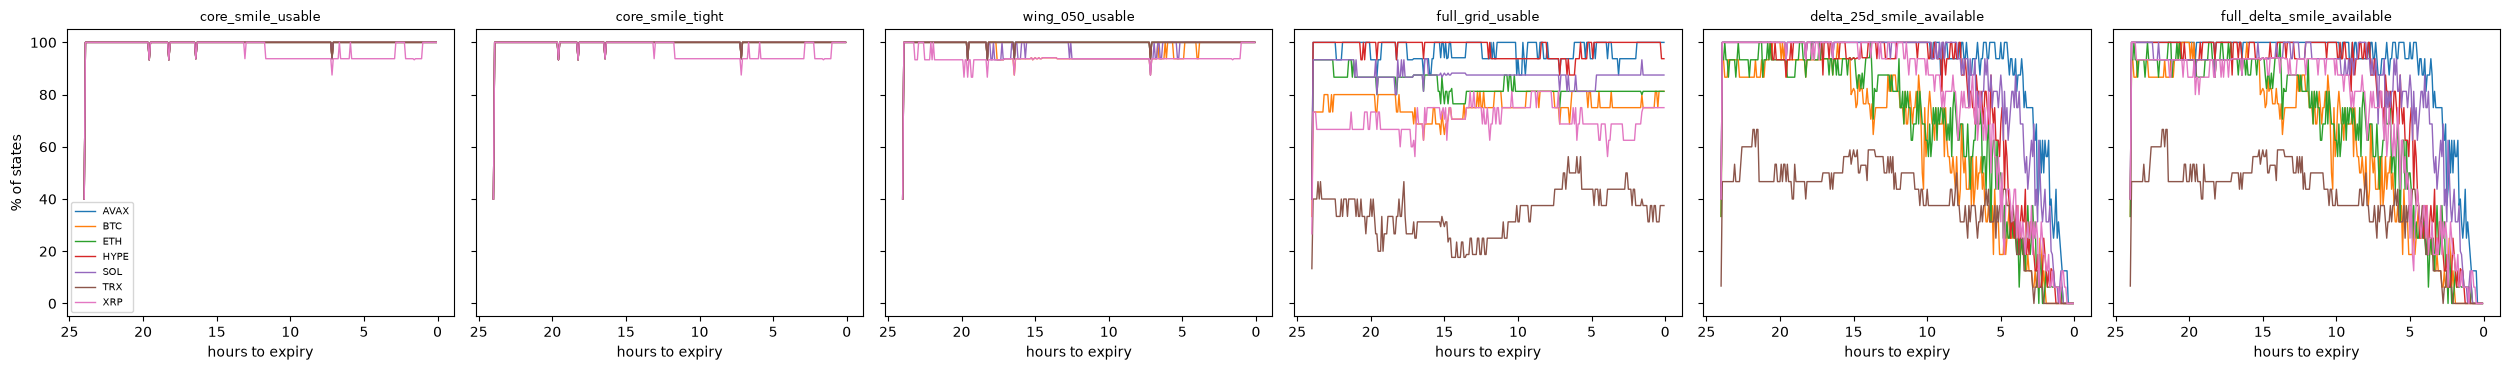

In [48]:
avail_cols = [c for c in [
    "core_smile_usable", "core_smile_tight", "wing_050_usable", "full_grid_usable",
    "delta_25d_smile_available", "full_delta_smile_available",
] if c in features.columns]

opt_rows = features[features["primary_option_family_id"].notna()] if "primary_option_family_id" in features.columns else features
availability = (
    opt_rows.assign(**{c: as_bool(opt_rows[c]) for c in avail_cols})
    .groupby(["underlying", "tte_bucket"], observed=True)[avail_cols]
    .mean()
    .mul(100)
    .round(1)
)
print("Share of states with a primary option family where each representation is available (%):")
display(availability)

if "core_smile_quality_tier" in features.columns:
    tiers = (
        opt_rows.groupby(["underlying", "core_smile_quality_tier"]).size()
        .unstack(fill_value=0)
    )
    display(tiers.div(tiers.sum(axis=1), axis=0).mul(100).round(1))

fig, axes = plt.subplots(1, len(avail_cols), figsize=(4.2 * len(avail_cols), 3.8), sharey=True)
for ax, col in zip(np.atleast_1d(axes), avail_cols):
    m = (
        opt_rows.assign(_v=as_bool(opt_rows[col]).astype(float))
        .groupby(["minutes_to_expiry", "underlying"])["_v"].mean().unstack()
        .sort_index(ascending=False)
    )
    for asset in m.columns:
        ax.plot(m.index / 60, 100 * m[asset], linewidth=1, label=asset)
    ax.invert_xaxis()
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("hours to expiry")
np.atleast_1d(axes)[0].set_ylabel("% of states")
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part B — Level Distributions

## 5. Pooled and per-asset distributions

ATM IV levels differ several-fold across assets, so pooled quantiles mainly describe the asset mix. The per-asset table is the relevant one.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,option_iv_atm_forward,31660,7.621382,47.924916,23.559319,0.801229,3.675181,8.654510,10.882055,13.349824,18.253836,44.588690,89.226408,109.259205,128.574730,457.556512
1,ALL,option_skew_025,31556,7.924837,3.217686,9.183137,8.082678,252.745926,-56.083210,-47.425761,-16.868270,-8.526105,2.972683,15.412164,24.652415,64.280729,379.486618
2,ALL,option_skew_050,31172,9.045285,4.412626,12.033800,0.997329,12.453369,-76.863050,-53.047888,-28.312951,-12.756692,4.060301,22.606584,36.420815,75.683268,140.380268
3,ALL,option_curvature_025,31556,7.924837,9.066853,8.103467,-3.075901,306.712352,-416.786227,-13.974938,-1.487461,0.816034,7.773807,21.857407,33.515847,50.789051,198.451851
4,ALL,option_curvature_050,31172,9.045285,20.126166,10.278333,-2.568603,130.429258,-405.665181,-4.113777,2.274147,6.604915,19.171465,36.580035,49.211449,68.723999,90.968362
5,ALL,option_local_skew_slope_025,31556,7.924837,64.353712,183.662739,8.082678,252.745926,-1121.664206,-948.515222,-337.365391,-170.522103,59.453668,308.243274,493.048292,1285.614586,7589.732356
6,ALL,option_local_skew_slope_050,31172,9.045285,44.126264,120.338002,0.997329,12.453369,-768.630504,-530.478879,-283.129509,-127.566924,40.603007,226.065842,364.208147,756.832676,1403.802684
7,ALL,iv_put_25d,26094,23.862045,50.946443,23.141953,0.774713,5.732046,10.949474,11.968842,14.130143,20.023461,49.637816,91.520535,110.652392,127.890432,512.549982
8,ALL,iv_call_25d,26597,22.394374,53.931047,24.816137,0.517022,-0.124688,12.329855,13.135089,15.703772,20.852367,53.328583,97.680597,119.773438,136.151195,244.626770
9,ALL,rr_25d,22741,33.645542,3.528018,6.037299,-20.283639,1779.383006,-474.442084,-16.068424,-7.047816,-3.445276,3.015242,12.271858,17.070469,27.087601,198.183963


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,option_iv_atm_forward,4525,7.577614,77.270151,19.684545,0.242276,-0.345441,37.049039,38.030465,39.084949,43.676090,77.331454,112.607749,126.144342,131.258317,134.990000
1,AVAX,option_skew_025,4525,7.577614,4.670064,7.431588,1.214770,14.893976,-44.400912,-36.316725,-18.287926,-3.906087,4.275250,15.464594,30.032035,63.843277,66.479585
2,AVAX,option_skew_050,4525,7.577614,8.337675,16.019959,2.154652,21.978352,-76.863050,-70.527689,-39.835894,-9.297705,7.022549,24.977934,57.053078,139.620000,140.380268
3,AVAX,option_curvature_025,4525,7.577614,5.220283,5.620918,3.038564,15.172769,-25.251217,-8.215346,-0.747107,0.799782,3.674700,15.902354,28.582732,49.442031,52.235120
4,AVAX,option_curvature_050,4525,7.577614,15.595933,10.277749,2.621067,10.973933,-18.175527,-2.401051,2.188903,5.233163,13.694663,32.349937,59.139212,88.190248,90.968362
5,AVAX,option_local_skew_slope_025,4525,7.577614,93.401288,148.631760,1.214770,14.893976,-888.018232,-726.334508,-365.758520,-78.121731,85.504996,309.291870,600.640691,1276.865534,1329.591705
6,AVAX,option_local_skew_slope_050,4525,7.577614,83.376748,160.199588,2.154652,21.978352,-768.630504,-705.276887,-398.358936,-92.977055,70.225488,249.779336,570.530783,1396.200000,1403.802684
7,AVAX,iv_put_25d,4236,13.480392,77.779931,19.572341,0.127793,-0.567989,37.265044,37.519925,39.035765,43.924657,77.989936,111.656386,122.391822,128.148084,131.211141
8,AVAX,iv_call_25d,4283,12.520425,82.354405,21.062771,0.265762,-0.338096,38.205691,39.283342,41.546083,46.854242,82.887240,121.247004,133.480500,138.808403,147.906102
9,AVAX,rr_25d,4081,16.646242,4.806050,4.043292,0.764590,6.021269,-19.501503,-14.189001,-4.115598,-0.657565,4.409370,11.514021,15.385017,28.976320,31.173967


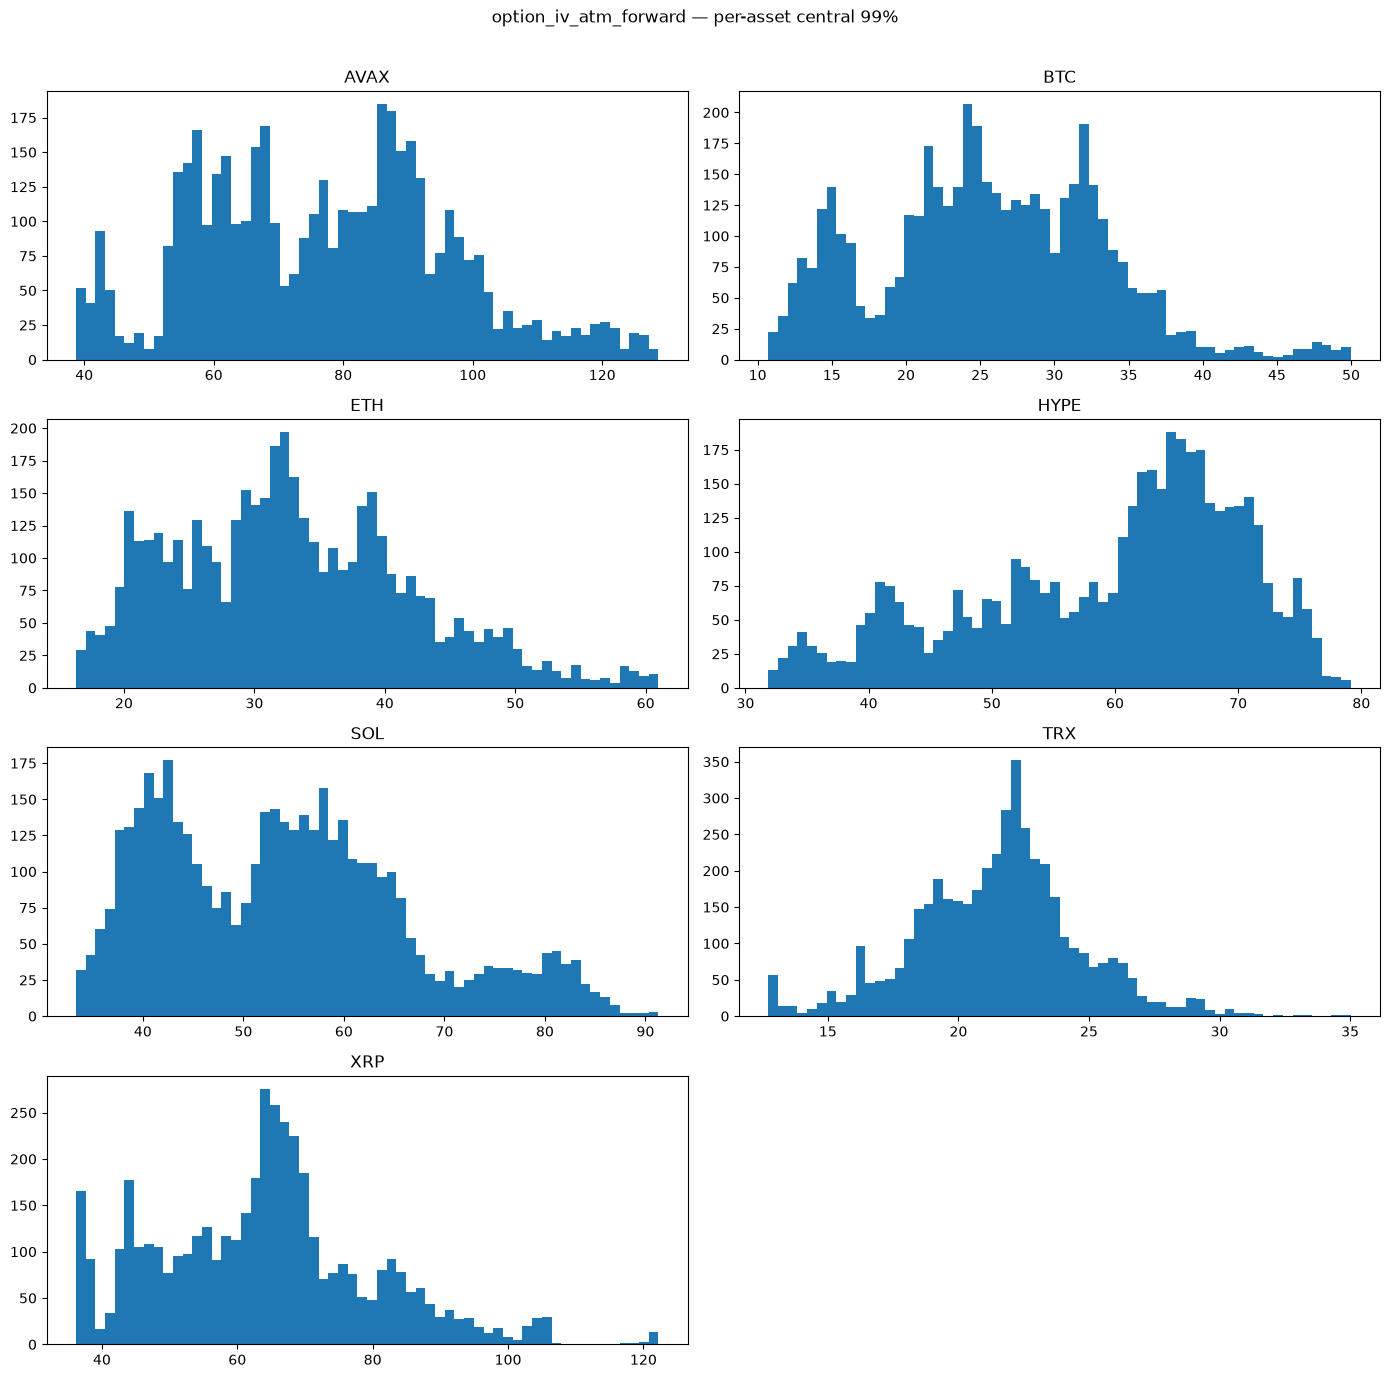

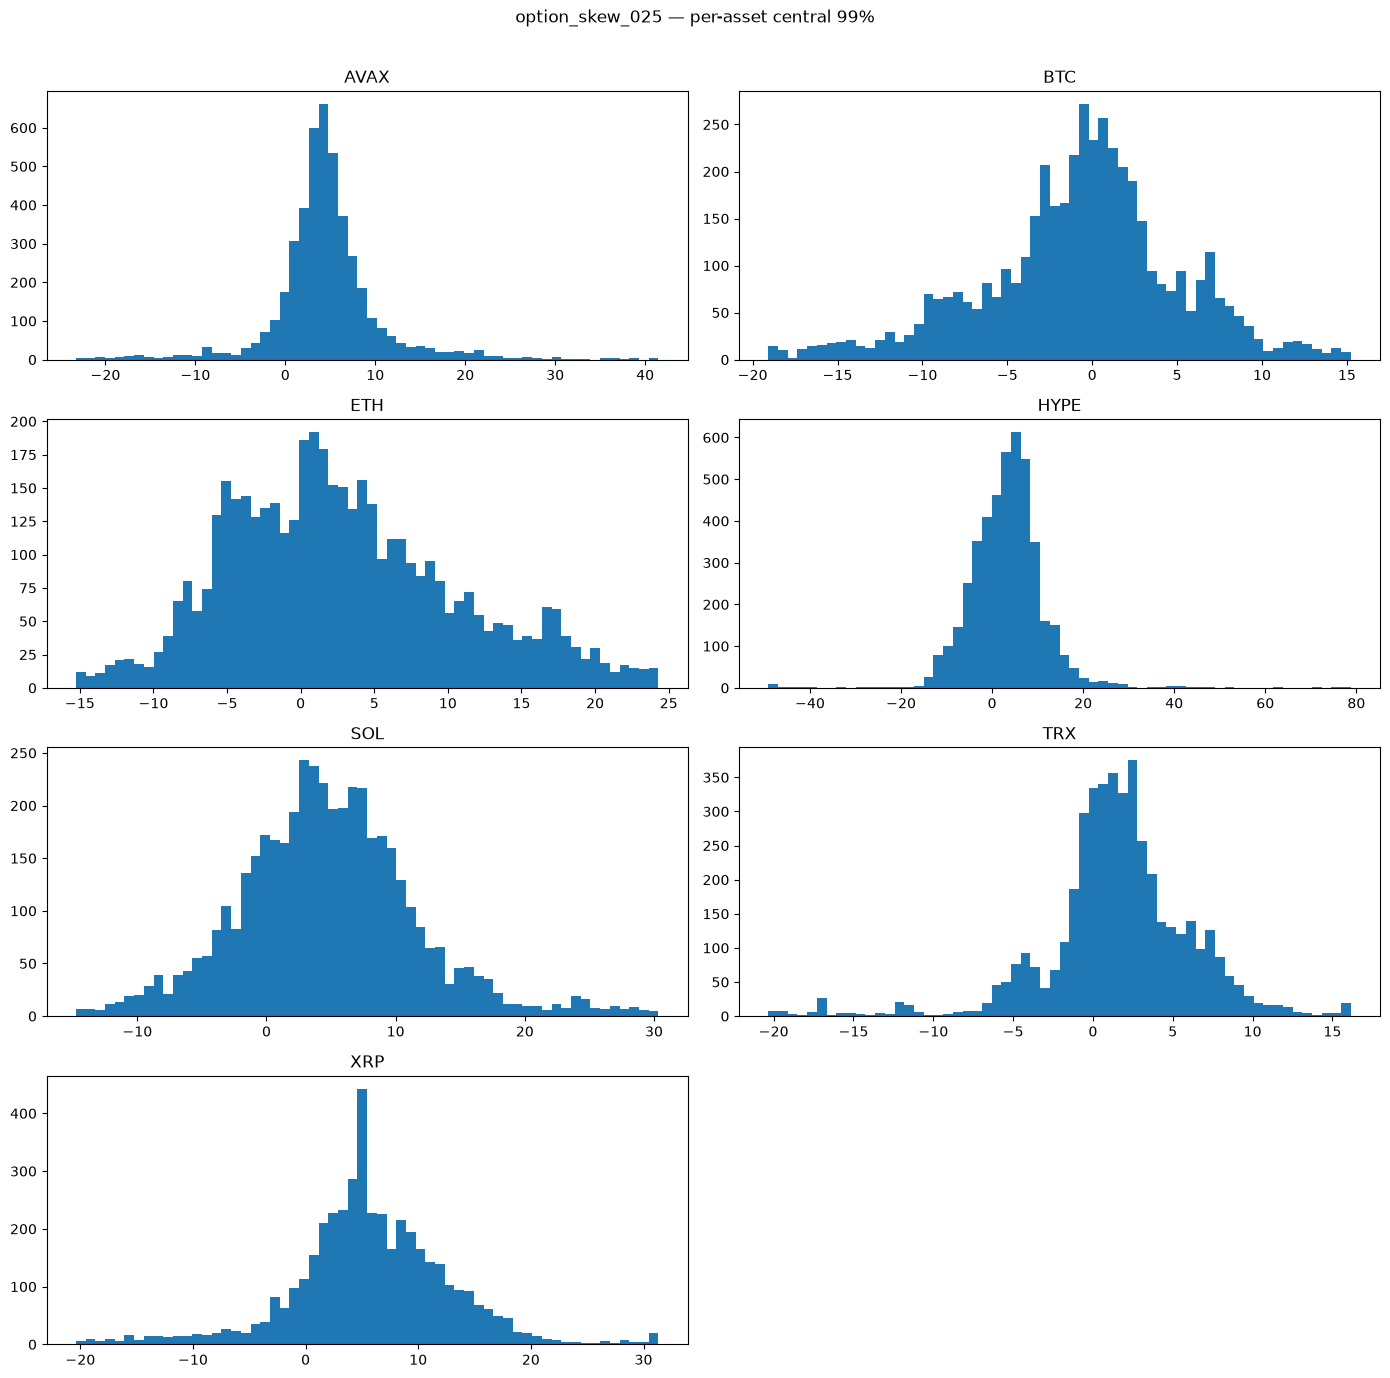

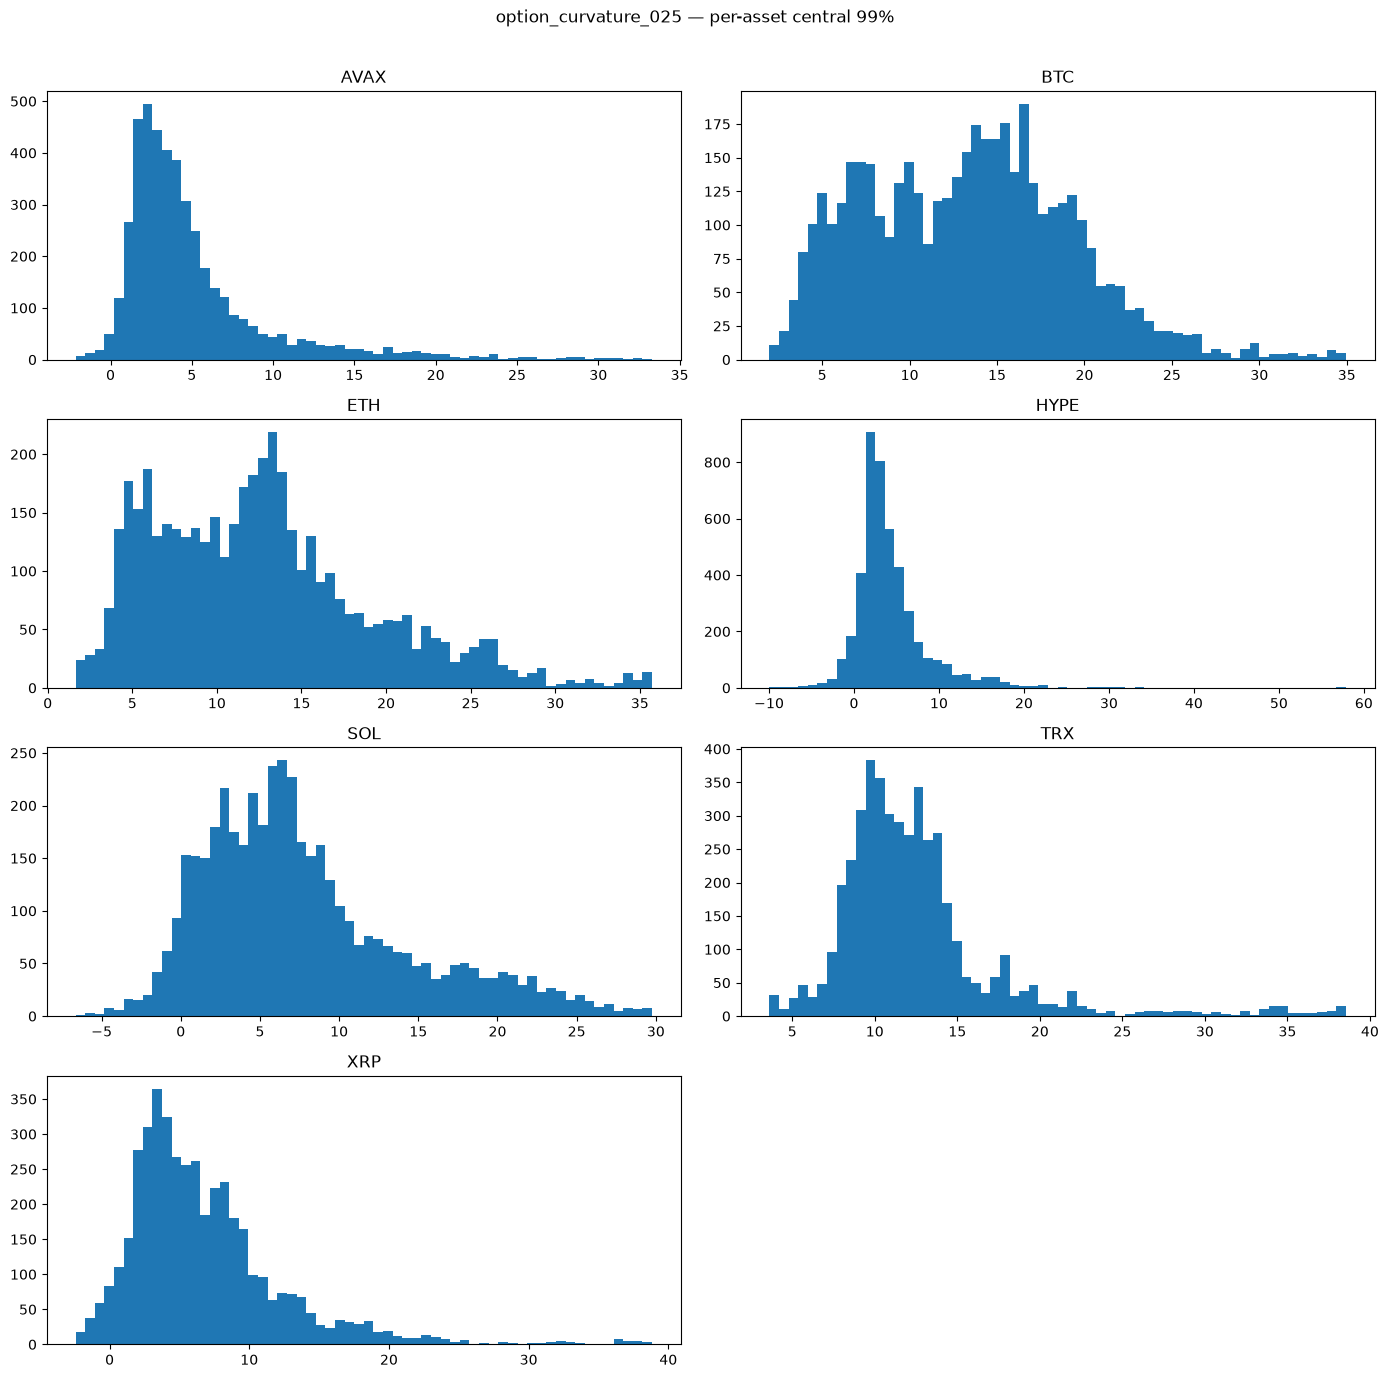

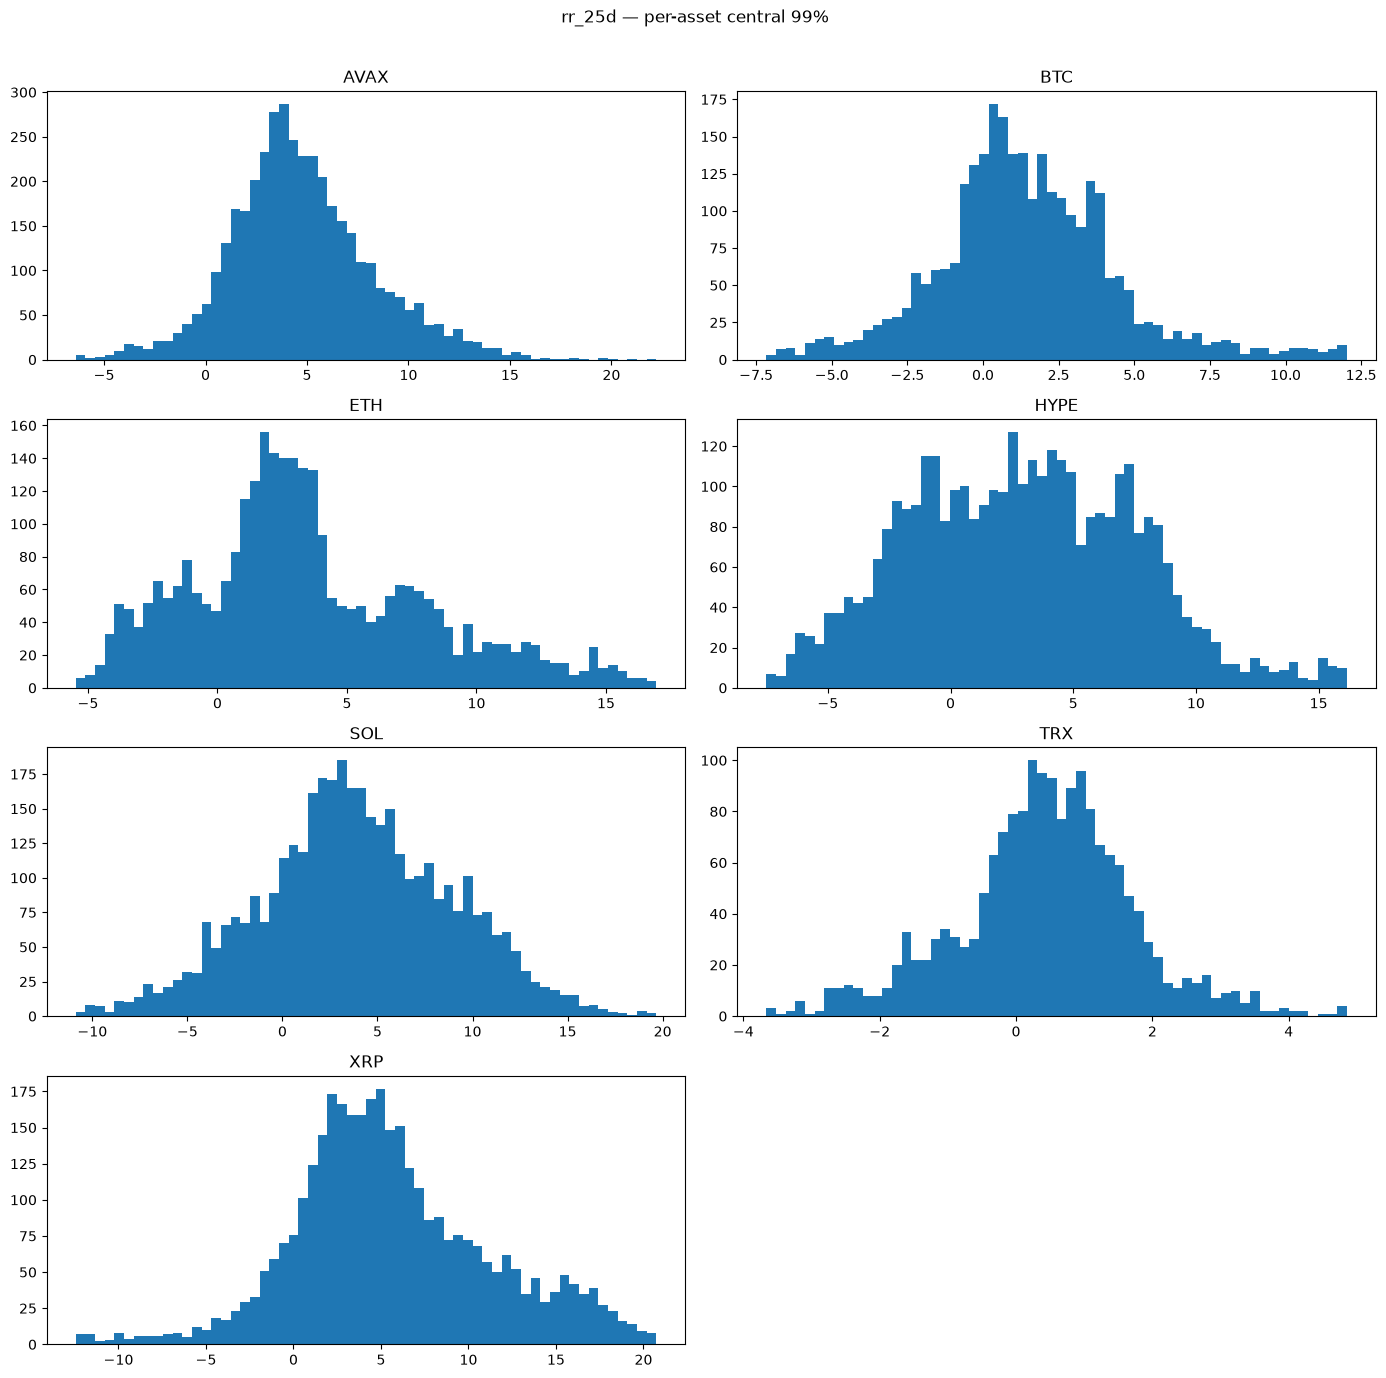

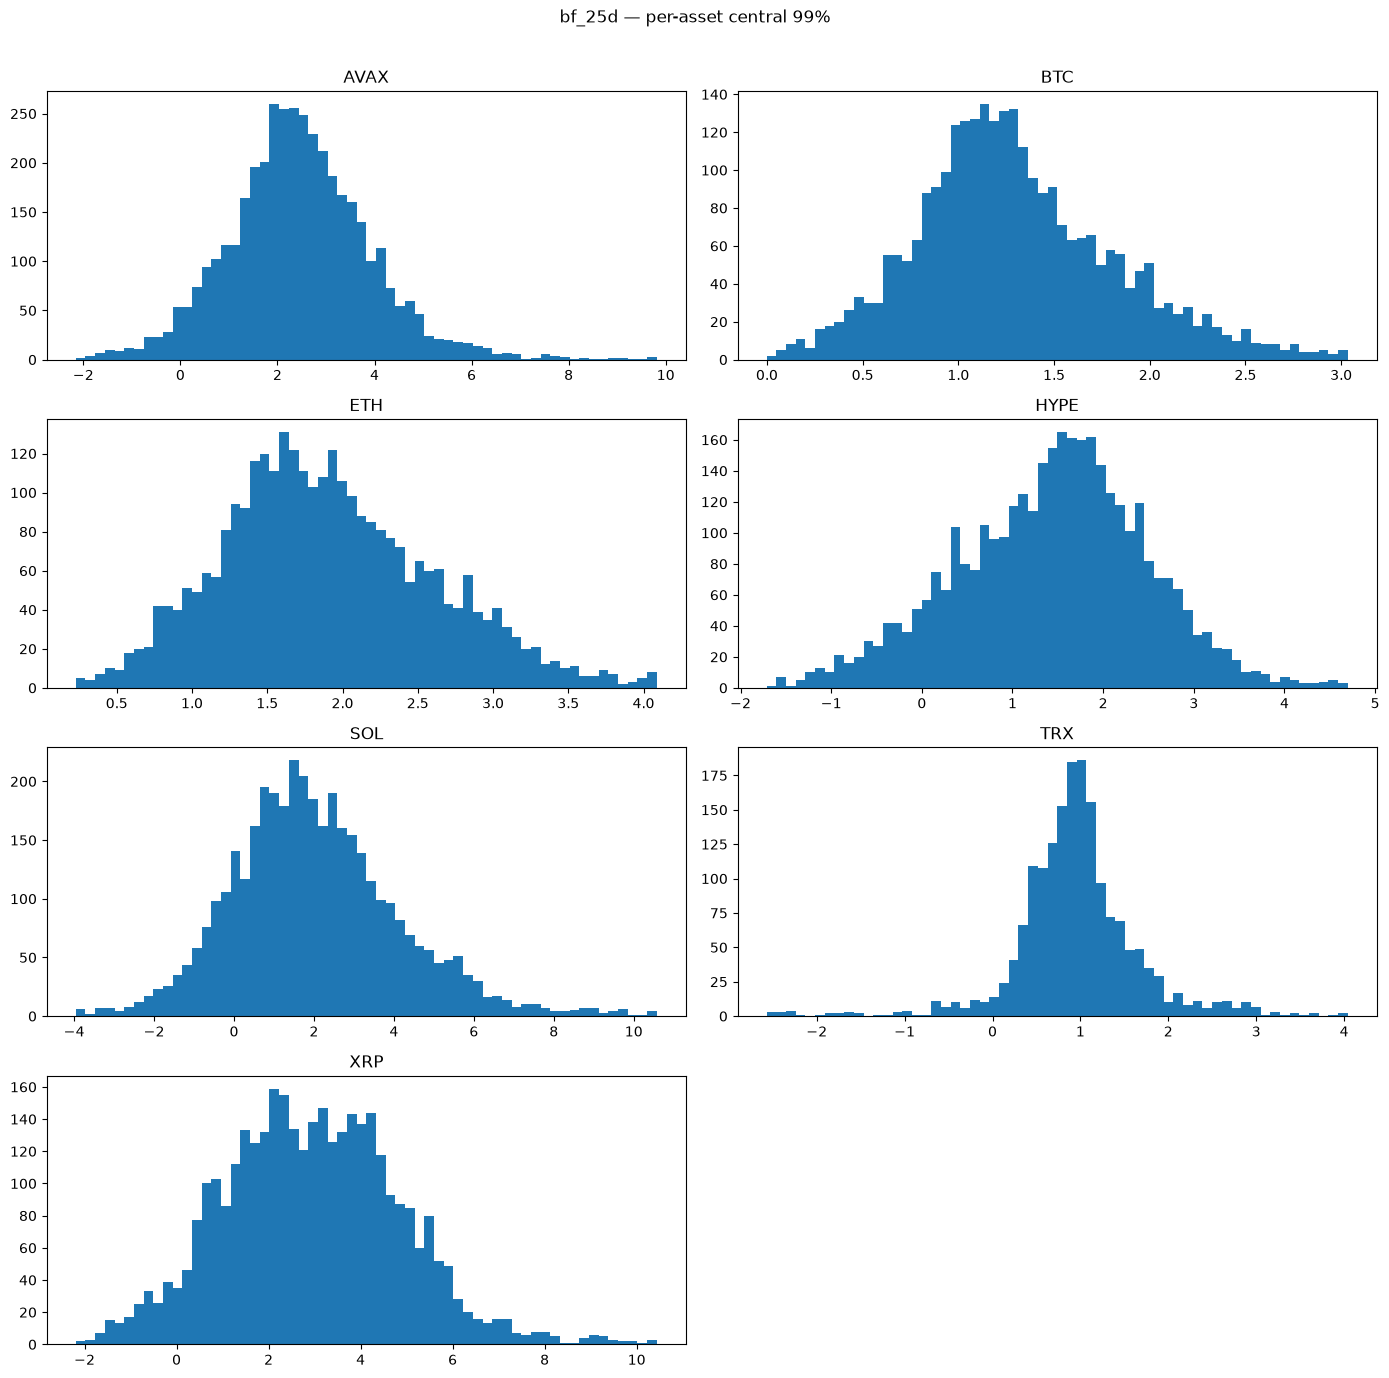

In [49]:
level_summary = feature_summary(features, OPTION_LEVEL)
level_by_asset = feature_summary(features, OPTION_LEVEL, group_col="underlying")
display(level_summary)
display(level_by_asset)

for col in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025", "rr_25d", "bf_25d"]:
    if col in features.columns:
        plot_asset_histograms(features, col)

# Part C — Does Fixed Log-Moneyness Mean the Same Thing All Session? (audit A2)

## 6. The ±2.5% node in units of expected move

A 0DTE option's one-standard-deviation move to expiry is $\sigma_{ATM}\sqrt{\tau}$, which shrinks through the session. The fixed node $k = \pm 2.5\%$ sits at

$$
z_{2.5\%} = \frac{0.025}{\sigma_{ATM}\,\sqrt{\tau}}
$$

standard deviations from the forward. If $z_{2.5\%}$ moves from about 1 in the morning to 5–10 near expiry, `option_skew_025` measures near-ATM skew early in the session and far-wing skew late in it. Its time-of-day profile is then mostly mechanical.

Median z of the ±2.5% node, by asset and time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,5.82,3.59,2.33,1.55,1.09,0.76,0.58
BTC,18.22,10.36,6.66,4.36,3.43,2.39,1.67
ETH,14.84,8.40,5.29,3.55,2.71,1.92,1.29
HYPE,7.53,4.23,2.73,1.98,1.34,0.99,0.75
SOL,7.91,4.47,3.05,2.19,1.59,1.13,0.85
TRX,19.27,11.46,7.05,4.98,3.88,2.88,2.28
XRP,7.27,4.27,2.65,1.83,1.32,0.93,0.74


Share of states where the ±2.5% node is more than 2, 3 or 5 expected moves away:


,states,beyond_2sd_pct,beyond_3sd_pct,beyond_5sd_pct
underlying,,,,
AVAX,4525,13.7,5.1,1.7
BTC,4525,77.1,50.7,20.8
ETH,4525,62.0,32.4,11.1
HYPE,4525,20.4,8.5,2.7
SOL,4525,25.1,10.1,3.0
TRX,4525,97.8,60.9,20.2
XRP,4510,18.1,7.7,2.6


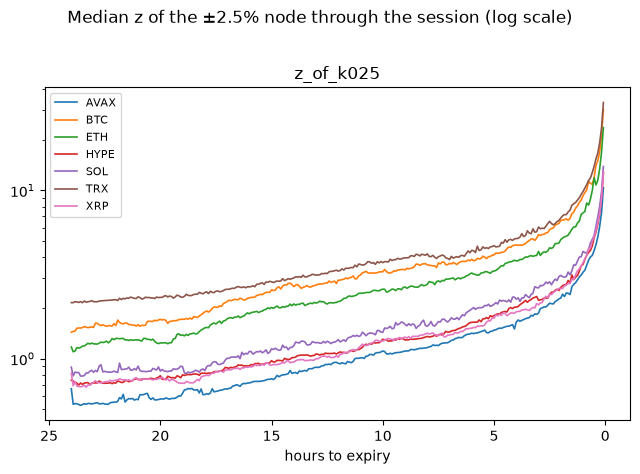

In [50]:
features["z_of_k025"] = 0.025 / features["atm_sigma_sqrt_t"]
features["z_of_k050"] = 0.050 / features["atm_sigma_sqrt_t"]

z_table = (
    features.groupby(["underlying", "tte_bucket"], observed=True)["z_of_k025"]
    .median()
    .unstack("tte_bucket")
    .round(2)
)
print("Median z of the ±2.5% node, by asset and time to expiry:")
display(z_table)

beyond = (
    features.dropna(subset=["z_of_k025"])
    .groupby("underlying")["z_of_k025"]
    .agg(
        states="count",
        beyond_2sd_pct=lambda s: 100 * (s > 2).mean(),
        beyond_3sd_pct=lambda s: 100 * (s > 3).mean(),
        beyond_5sd_pct=lambda s: 100 * (s > 5).mean(),
    )
    .round(1)
)
print("Share of states where the ±2.5% node is more than 2, 3 or 5 expected moves away:")
display(beyond)

plot_median_by_tte(features, ["z_of_k025"], "Median z of the ±2.5% node through the session (log scale)", logy=True)

## 7. Mechanical drift of fixed-$k$ features

If fixed-$k$ features were stationary through the session, their median would be flat in time to expiry. The plots and the $\eta^2$ table measure how much of each feature's variance the clock bucket explains, per asset:

$$
\eta^2 = \frac{\sum_t (\bar x_{b(t)} - \bar x)^2}{\sum_t (x_t - \bar x)^2}
$$

where $\bar x_{b(t)}$ is the mean of the feature in the time-to-expiry bucket of state $t$. A high $\eta^2$ means the feature mostly encodes the clock. Part D compares this with the standardized-moneyness prototype.

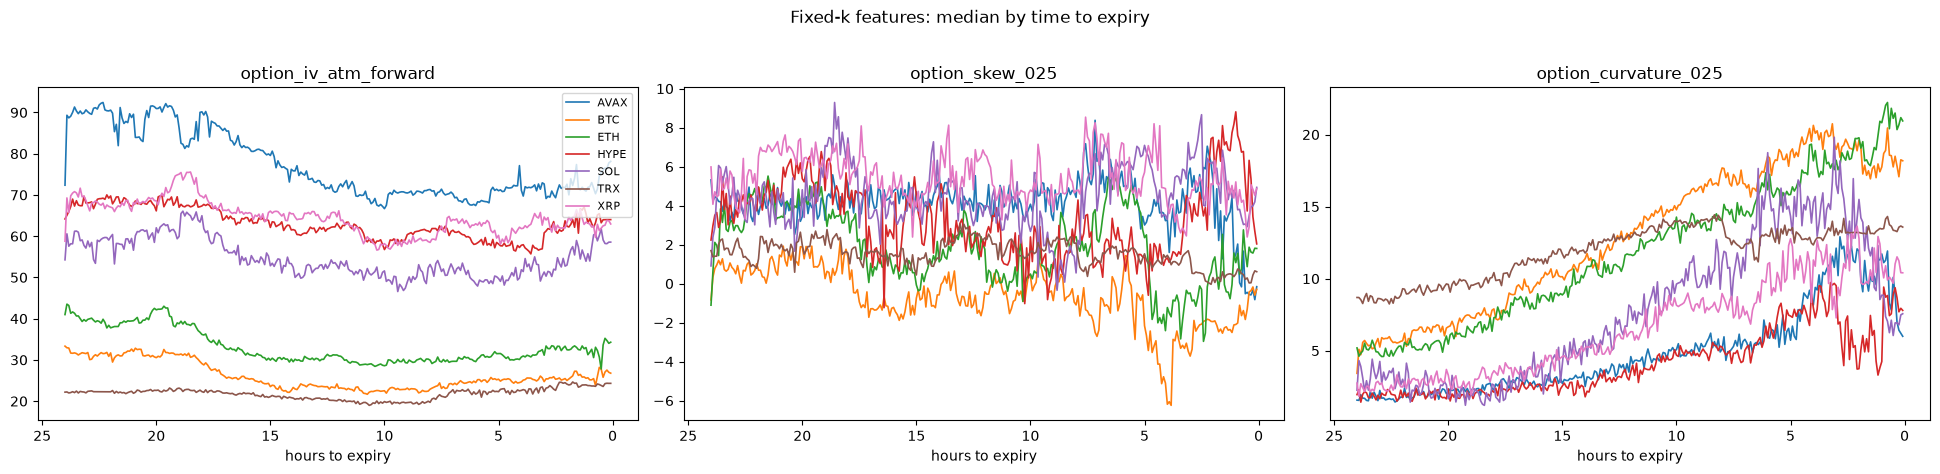

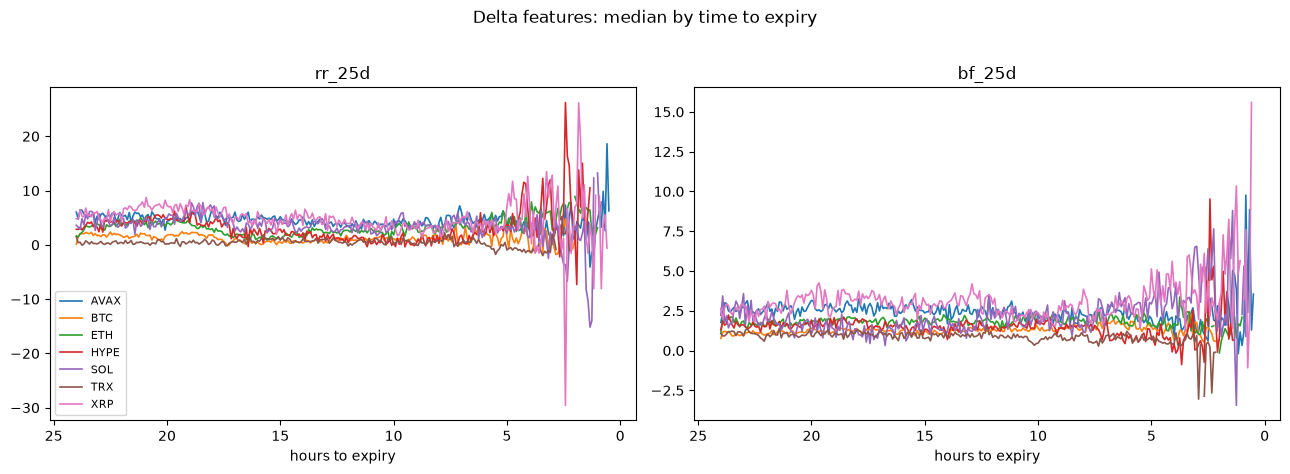

η² of the time-to-expiry bucket, per asset (fixed-k and delta features):


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
bf_10d,0.078,0.002,0.011,0.063,0.145,0.028,0.012
bf_25d,0.034,0.002,0.002,0.026,0.090,0.072,0.027
iv_call_10d,0.080,0.076,0.082,0.085,0.017,0.031,0.065
iv_call_25d,0.053,0.107,0.069,0.067,0.042,0.157,0.075
iv_put_10d,0.045,0.059,0.075,0.051,0.007,0.048,0.019
iv_put_25d,0.051,0.035,0.062,0.071,0.058,0.091,0.039
option_curvature_025,0.359,0.299,0.419,0.107,0.419,0.191,0.329
option_curvature_050,0.379,0.201,0.269,0.261,0.321,0.053,0.400
option_iv_atm_forward,0.049,0.059,0.075,0.067,0.061,0.114,0.050


In [51]:
plot_median_by_tte(
    features,
    [c for c in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025"] if c in features.columns],
    "Fixed-k features: median by time to expiry",
)
plot_median_by_tte(
    features,
    [c for c in ["rr_25d", "bf_25d"] if c in features.columns],
    "Delta features: median by time to expiry",
)

eta_rows = []
for asset, g in features.groupby("underlying"):
    for col in [c for c in OPTION_LEVEL if c in g.columns]:
        eta_rows.append({"underlying": asset, "feature": col, "eta2_tte": eta_squared(g, col)})
eta_fixed = pd.DataFrame(eta_rows).pivot(index="feature", columns="underlying", values="eta2_tte")
print("η² of the time-to-expiry bucket, per asset (fixed-k and delta features):")
display(eta_fixed.round(3))

# Part D — What the Surface Is Made Of (audit B2)

## 8. Node-level IV source

The preferred surface takes, per contract, the bid/ask IV midpoint when both sides exist, and otherwise Deribit's `mark_iv`. Each interpolated node is bracketed by two contracts. A node is classified as:

- **quote:** both bracketing contracts use the bid/ask midpoint;
- **mark:** both use Deribit's mark model;
- **mixed:** one of each.

A mark-sourced node reflects Deribit's own pricing model, not traded or quoted prices. The long-form query below joins `smile_node_state` to `normalized_option_chain` for the primary option family. It is the slowest step in the notebook.

In [52]:
nodes = q(
    """
    WITH prim AS (
        SELECT DISTINCT option_family_id
        FROM primary_option_surface_feature_state
    ),
    chain AS MATERIALIZED (
        SELECT n.state_id, n.instrument_name, n.preferred_iv_source
        FROM normalized_option_chain n
        JOIN prim p ON n.option_family_id = p.option_family_id
        WHERE n.surface_base_eligible
    ),
    nodes AS (
        SELECT
            s.state_id, s.state_time, s.underlying, s.session_id, s.minutes_to_expiry,
            s.option_family_id, s.target_log_moneyness, s.interpolated_iv,
            s.interpolation_span_log_moneyness,
            s.left_instrument_name, s.right_instrument_name
        FROM smile_node_state s
        JOIN prim p ON s.option_family_id = p.option_family_id
        WHERE s.surface_source = 'preferred'
          AND s.interpolated_iv IS NOT NULL
    )
    SELECT
        nodes.* EXCLUDE (left_instrument_name, right_instrument_name),
        l.preferred_iv_source AS left_source,
        r.preferred_iv_source AS right_source
    FROM nodes
    LEFT JOIN chain l ON l.state_id = nodes.state_id AND l.instrument_name = nodes.left_instrument_name
    LEFT JOIN chain r ON r.state_id = nodes.state_id AND r.instrument_name = nodes.right_instrument_name
    """,
    "preferred smile nodes with source",
)
nodes["state_time"] = pd.to_datetime(nodes["state_time"], utc=True)
is_quote = lambda s: s.eq("bid_ask_iv_mid")
nodes["node_source"] = np.select(
    [is_quote(nodes["left_source"]) & is_quote(nodes["right_source"]),
     nodes["left_source"].eq("mark_iv") & nodes["right_source"].eq("mark_iv")],
    ["quote", "mark"],
    default="mixed",
)
nodes["tte_bucket"] = pd.cut(nodes["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)

core = nodes[nodes["target_log_moneyness"].round(4).isin([-0.025, 0.0, 0.025])]
mark_share = (
    core.assign(any_mark=core["node_source"].ne("quote"))
    .groupby(["underlying", "tte_bucket"], observed=True)["any_mark"]
    .mean().mul(100).unstack("tte_bucket").round(1)
)
print("Core nodes (k = 0, ±2.5%) with at least one mark-sourced side, % — by asset and time to expiry:")
display(mark_share)

by_node = (
    nodes.assign(any_mark=nodes["node_source"].ne("quote"))
    .groupby(["underlying", "target_log_moneyness"])["any_mark"]
    .mean().mul(100).unstack("target_log_moneyness").round(1)
)
print("All nodes with at least one mark-sourced side, % — by asset and node:")
display(by_node)

print("Node source composition, all nodes:")
display(pd.crosstab(nodes["underlying"], nodes["node_source"], normalize="index").mul(100).round(1))

[preferred smile nodes with source] 214,225 rows in 20.3s
Core nodes (k = 0, ±2.5%) with at least one mark-sourced side, % — by asset and time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,98.3,90.3,67.5,41.3,9.7,2.2,3.9
BTC,100.0,95.8,78.9,65.3,50.9,26.1,10.6
ETH,100.0,96.5,77.3,62.6,40.0,11.3,2.6
HYPE,100.0,95.5,76.2,54.4,19.0,6.7,7.0
SOL,100.0,98.6,87.4,68.8,43.4,28.7,17.4
TRX,100.0,100.0,97.7,87.8,72.5,58.1,39.7
XRP,99.7,96.9,84.9,56.4,37.7,10.7,14.6


All nodes with at least one mark-sourced side, % — by asset and node:


target_log_moneyness,-0.100,-0.050,-0.025,0.000,0.025,0.050,0.100
underlying,,,,,,,
AVAX,76.8,45.0,25.8,8.4,22.5,37.5,69.4
BTC,96.9,84.4,55.0,8.4,60.4,91.8,100.0
ETH,97.2,74.9,45.5,7.7,43.8,70.5,98.8
HYPE,93.6,73.3,35.5,9.4,32.2,64.0,95.3
SOL,100.0,91.9,62.4,12.9,53.2,88.0,99.6
TRX,100.0,99.4,93.5,25.6,79.9,98.6,100.0
XRP,99.1,71.4,47.8,14.8,40.0,66.3,92.5


Node source composition, all nodes:


node_source,mark,mixed,quote
underlying,,,
AVAX,34.2,6.4,59.4
BTC,61.0,8.9,30.1
ETH,54.0,7.7,38.2
HYPE,46.1,11.4,42.5
SOL,62.4,9.7,28.0
TRX,72.7,11.1,16.2
XRP,50.3,10.0,39.6


## 9. Do source switches create artificial changes?

Consecutive states (same session, exactly 5 minutes apart) are compared at the ATM node and at the ±2.5% nodes. If the node source changes between the two states (for example quote → mark because a bid disappeared), the IV change mixes a market move with a model switch.

If the dispersion of changes with a source switch is much larger than without one, the pipeline should compute changes only when both endpoints share a source, as audit B2 proposed.

In [53]:
nd = nodes.sort_values(["underlying", "target_log_moneyness", "state_time"]).copy()
grp = nd.groupby(["underlying", "target_log_moneyness"], sort=False)
nd["prev_iv"] = grp["interpolated_iv"].shift(1)
nd["prev_source"] = grp["node_source"].shift(1)
nd["prev_time"] = grp["state_time"].shift(1)
nd["prev_session"] = grp["session_id"].shift(1)
ok = (
    (nd["state_time"] - nd["prev_time"] == pd.Timedelta(minutes=5))
    & (nd["session_id"] == nd["prev_session"])
)
nd = nd[ok].copy()
nd["d_iv"] = nd["interpolated_iv"] - nd["prev_iv"]
nd["transition"] = np.where(
    nd["node_source"] == nd["prev_source"], "same:" + nd["node_source"], "switch"
)

switch_summary = (
    nd[nd["target_log_moneyness"].round(4).isin([-0.025, 0.0, 0.025])]
    .groupby(["underlying", "transition"])["d_iv"]
    .agg(
        n="count",
        std="std",
        mad=lambda s: 1.4826 * (s - s.median()).abs().median(),
        p99_abs=lambda s: s.abs().quantile(0.99),
    )
    .round(4)
)
print("Core-node 5m IV changes by source transition:")
display(switch_summary)

switch_share = (
    nd.assign(sw=nd["transition"].eq("switch"))
    .groupby(["underlying", "tte_bucket"], observed=True)["sw"]
    .mean().mul(100).unstack("tte_bucket").round(1)
)
print("Share of node changes that cross a source switch, % — by time to expiry:")
display(switch_share)

Core-node 5m IV changes by source transition:


n      std     mad  p99_abs
underlying transition                                 
AVAX       same:mark    1693   1.8571  0.3545   8.7238
           same:mixed    415   3.2513  1.2930  12.4987
           same:quote  10748   1.8995  1.0032   7.6366
           switch        641   6.5059  2.5344  28.3957
BTC        same:mark    3785   0.6161  0.2202   2.3836
           same:mixed   1340   1.5876  0.5569   4.0953
           same:quote   7768   0.7279  0.4956   2.4919
           switch        604  17.2618  1.0101  10.5732
ETH        same:mark    2779   0.8710  0.3808   3.3661
           same:mixed   1085   0.9432  0.4866   3.4047
           same:quote   8981   1.7791  0.5776   3.2378
           switch        652  12.8809  1.1586   9.0273
HYPE       same:mark    1741   1.1898  0.2969   4.3399
           same:mixed   1086   3.1022  0.8856  15.5577
           same:quote   9746   4.1195  0.8475   9.2408
           switch        924  12.7548  2.1605  23.2375
SOL        same:mark    3440   1.2517  0.3721   5.2489
           same:mixed   1585   3.1628  0.9088   9.5588
           same:quote   7427   2.5421  1.8214   8.6879
           switch       1045   5.3277  2.3510  24.3218
TRX        same:mark    5950   0.3347  0.0813   1.3241
           same:mixed   2696   0.6518  0.1869   2.7728
           same:quote   4449   0.6392  0.3880   2.2017
           switch        402   1.2408  0.5780   4.9345
XRP        same:mark    2648   1.4417  0.2818   6.0290
           same:mixed   1307   2.5220  0.9406  10.0207
           same:quote   8528   1.7521  1.1585   5.9486
           switch        872   4.0927  1.9299  16.5593

Share of node changes that cross a source switch, % — by time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,1.9,3.7,5.6,5.6,4.6,4.1,4.7
BTC,1.7,3.1,2.2,2.0,2.6,4.3,3.6
ETH,2.0,4.3,2.3,2.7,4.2,4.8,3.0
HYPE,0.7,4.8,5.0,6.6,6.7,7.4,6.6
SOL,1.2,4.4,3.3,3.3,4.7,6.0,5.4
TRX,0.0,0.3,0.7,1.6,1.0,1.9,2.9
XRP,1.1,2.5,3.1,5.5,4.3,4.9,6.7


# Part E — Standardized-Moneyness Prototype

## 10. Build a $z$-grid from the long-form chain

For each state of the primary family, every surface-eligible OTM contract (puts below the forward, calls above) is placed at

$$
z = \frac{\ln(K/F)}{\sigma_{ATM}\sqrt{\tau}}
$$

and IV is interpolated linearly in $k$ to the nodes $z \in \{-1, -0.5, 0, 0.5, 1\}$. As in the production grid, there is **no extrapolation**: a node exists only if strikes bracket it.

Two quality measures are kept per node:

- the interpolation span in $z$ units (near expiry, strike spacing becomes large relative to $\sigma\sqrt\tau$, so a $z$-node may sit between two distant strikes);
- whether the bracketing contracts are quote- or mark-sourced.

This is the honest trade-off of $z$-space: it fixes the meaning of each node, but near expiry the strike grid is coarse in $z$.

In [54]:
Z_NODES = [-1.0, -0.5, 0.0, 0.5, 1.0]

chain = q(
    """
    WITH prim AS (
        SELECT DISTINCT option_family_id FROM primary_option_surface_feature_state
    )
    SELECT
        n.state_id,
        n.log_moneyness,
        n.preferred_iv,
        n.preferred_iv_source
    FROM normalized_option_chain n
    JOIN prim p ON n.option_family_id = p.option_family_id
    WHERE n.surface_base_eligible
      AND n.preferred_iv > 0
      AND n.log_moneyness IS NOT NULL
    """,
    "long-form primary chain",
)

scale = (
    features[["state_id", "atm_sigma_sqrt_t"]]
    .dropna()
    .query("atm_sigma_sqrt_t > 0")
    .set_index("state_id")["atm_sigma_sqrt_t"]
)
chain = chain[chain["state_id"].isin(scale.index)]
chain = chain.sort_values(["state_id", "log_moneyness"]).reset_index(drop=True)
state_codes, state_index = pd.factorize(chain["state_id"], sort=False)
OFFSET = 10.0  # |log-moneyness| < 5 for any listed strike
key = state_codes * OFFSET + chain["log_moneyness"].to_numpy()
assert np.all(np.diff(key) >= 0), "chain must be sorted by state, then k"

iv = chain["preferred_iv"].to_numpy()
src_quote = chain["preferred_iv_source"].eq("bid_ask_iv_mid").to_numpy()
k_arr = chain["log_moneyness"].to_numpy()
n = len(chain)
s_state = scale.reindex(state_index).to_numpy()
codes_target = np.arange(len(state_index))

z_out = pd.DataFrame({"state_id": state_index})
for z in Z_NODES:
    k_target = z * s_state
    tkey = codes_target * OFFSET + k_target
    pos = np.searchsorted(key, tkey, side="left")
    pos_c = np.clip(pos, 0, n - 1)
    # Exact hit: compare on the state code and raw k, not on the packed key
    # (the packed key loses precision at large state codes).
    exact = (pos < n) & (state_codes[pos_c] == codes_target) & (np.abs(k_arr[pos_c] - k_target) <= 1e-12)
    right = np.where(exact, pos_c, pos)
    left = np.where(exact, pos_c, pos - 1)
    valid = (left >= 0) & (right < n)
    left_c, right_c = np.clip(left, 0, n - 1), np.clip(right, 0, n - 1)
    valid &= (state_codes[left_c] == codes_target) & (state_codes[right_c] == codes_target)
    span_k = k_arr[right_c] - k_arr[left_c]
    w = np.where(span_k > 0, (k_target - k_arr[left_c]) / np.where(span_k > 0, span_k, 1.0), 0.0)
    iv_z = iv[left_c] + w * (iv[right_c] - iv[left_c])
    tag = "00" if z == 0 else f"{z:+.1f}".replace("+", "p").replace("-", "m").replace(".", "")
    z_out[f"iv_z_{tag}"] = np.where(valid, iv_z, np.nan)
    z_out[f"span_z_{tag}"] = np.where(valid, span_k / s_state, np.nan)
    z_out[f"quote_z_{tag}"] = np.where(valid, src_quote[left_c] & src_quote[right_c], np.nan)

z_out["z_skew_05"] = z_out["iv_z_p05"] - z_out["iv_z_m05"]
z_out["z_skew_10"] = z_out["iv_z_p10"] - z_out["iv_z_m10"]
z_out["z_curv_05"] = (z_out["iv_z_p05"] + z_out["iv_z_m05"]) / 2 - z_out["iv_z_00"]
z_out["z_curv_10"] = (z_out["iv_z_p10"] + z_out["iv_z_m10"]) / 2 - z_out["iv_z_00"]
z_out["z_max_span_05"] = z_out[["span_z_m05", "span_z_00", "span_z_p05"]].max(axis=1)
z_out["z_max_span_10"] = z_out[["span_z_m10", "span_z_00", "span_z_p10"]].max(axis=1)

zf = features.merge(z_out, on="state_id", how="left")

# Consistency check: the z = 0 node must equal the pipeline's ATM IV (both are k = 0).
chk = zf[["iv_z_00", "option_iv_atm_forward"]].dropna()
diff = (chk.iloc[:, 0] - chk.iloc[:, 1]).abs()
print(f"z=0 vs pipeline ATM IV: n={len(chk):,} | identical (<1e-6): {100 * (diff < 1e-6).mean():.2f}% | max |diff| = {diff.max():.3e}")
print("Any mismatch must come from tie-breaking between a put and a call at the same strike; inspect if large.")
print(f"States with a z-grid: {z_out['iv_z_00'].notna().sum():,} of {len(z_out):,}")

[long-form primary chain] 961,260 rows in 4.0s
z=0 vs pipeline ATM IV: n=31,660 | identical (<1e-6): 100.00% | max |diff| = 0.000e+00
Any mismatch must come from tie-breaking between a put and a call at the same strike; inspect if large.
States with a z-grid: 31,660 of 31,660


## 11. Coverage and interpolation quality of the $z$-grid

A $z$-node bracketed by strikes several $\sigma\sqrt\tau$ apart is mostly an interpolation artifact. The table reports node availability and the median span in $z$ units by time to expiry. A practical acceptance rule would be a maximum span in $z$ (for example 1.0) — the table shows what such a rule would cost.

In [55]:
z_cov = (
    zf.groupby(["underlying", "tte_bucket"], observed=True)
    .agg(
        states=("state_id", "count"),
        z05_available_pct=("z_skew_05", lambda s: 100 * s.notna().mean()),
        z10_available_pct=("z_skew_10", lambda s: 100 * s.notna().mean()),
        median_span_z05=("z_max_span_05", "median"),
        span_z05_le_1_pct=("z_max_span_05", lambda s: 100 * (s <= 1.0).mean()),
        quote_atm_pct=("quote_z_00", lambda s: 100 * s.mean()),
    )
    .round(2)
)
display(z_cov)

kcov = (
    features.assign(core=as_bool(features["core_smile_usable"]) if "core_smile_usable" in features.columns else False)
    .groupby(["underlying", "tte_bucket"], observed=True)["core"].mean().mul(100).round(1)
    .unstack("tte_bucket")
)
print("For comparison — fixed-k core usable (%):")
display(kcov)

states  z05_available_pct  z10_available_pct  median_span_z05  span_z05_le_1_pct  quote_atm_pct
underlying tte_bucket                                                                                                    
AVAX       ≤30m (settle)     102              94.12              94.12             2.21               1.96           5.21
           30m–1h            102              94.12              94.12             1.41              10.78          29.17
           1–3h              408              93.87              93.87             0.91              62.01          64.75
           3–6h              612              94.12              94.12             0.62              89.22          95.83
           6–12h            1224              94.04              94.04             0.47              94.04          98.78
           12–18h           1224              94.28              94.28             0.33              94.28          99.13
           18–24h           1224              87.34              87.34             0.25              87.34          96.45
BTC        ≤30m (settle)     102              94.12              94.12             4.38               0.00           0.00
           30m–1h            102              94.12              94.12             2.57               0.00          12.50
           1–3h              408              93.87              93.87             1.73               1.47          60.31
           3–6h              612              94.12              94.12             1.13              34.31          95.49
           6–12h            1224              94.04              94.04             0.84              66.01          99.74
           12–18h           1224              94.28              94.28             0.59              85.13          99.91
           18–24h           1224              87.25              87.25             0.42              84.31          98.22
ETH        ≤30m (settle)     102              94.12              94.12             4.23               0.00           0.00
           30m–1h            102              94.12              94.12             2.55               0.98          10.42
           1–3h              408              93.87              93.87             1.61               4.17          67.62
           3–6h              612              94.12              94.12             1.11              35.78          96.35
           6–12h            1224              94.04              94.04             0.83              72.47         100.00
           12–18h           1224              94.28              94.28             0.60              93.22          99.83
           18–24h           1224              87.34              87.25             0.41              87.34          98.22
HYPE       ≤30m (settle)     102              94.12              94.12             3.27               0.00           0.00
           30m–1h            102              94.12              94.12             1.86               0.00          12.50
           1–3h              408              93.87              93.87             1.25              15.69          61.10
           3–6h              612              94.12              94.12             0.91              59.80          90.97
           6–12h            1224              94.04              94.04             0.61              85.87          98.96
           12–18h           1224              94.28              94.28             0.44              94.28          99.83
           18–24h           1224              87.34              87.34             0.35              87.34          97.10
SOL        ≤30m (settle)     102              94.12              94.12             2.78               0.00           0.00
           30m–1h            102              94.12              94.12             1.63               1.96           4.17
           1–3h              408              93.87              93.87             1.07              34.31          36.81


For comparison — fixed-k core usable (%):


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,94.1,94.1,93.9,94.1,94.0,94.3,87.3
BTC,94.1,94.1,93.9,94.1,94.0,94.3,87.3
ETH,94.1,94.1,93.9,94.1,94.0,94.3,87.3
HYPE,94.1,94.1,93.9,94.1,94.0,94.3,87.3
SOL,94.1,94.1,93.9,94.1,94.0,94.3,87.3
TRX,94.1,94.1,93.9,94.1,94.0,94.3,87.3
XRP,94.1,94.1,90.0,88.4,88.6,94.2,87.3


## 12. Is the $z$-grid more stationary through the session?

The same $\eta^2$ diagnostic as Section 7, now comparing fixed-$k$ and $z$ features on the states where both exist. Skew and curvature are also shown **relative to ATM IV**, because ATM IV itself has an intraday profile.

Reading the result:

- if $z$-features have clearly lower $\eta^2$ than their fixed-$k$ counterparts, the fixed-$k$ grid is mostly measuring the clock and audit A2 holds;
- if they are similar, the fixed-$k$ grid is not the main source of TTE dependence, and the remaining profile is genuine intraday seasonality (to be removed by the clock baseline in the framework's Step 2).

,underlying,measure,n_both,eta2_fixed_k,eta2_z,z_minus_k
0,AVAX,skew,4525,0.005,0.068,0.063
1,AVAX,curvature,4525,0.359,0.039,-0.321
2,AVAX,skew / ATM,4525,0.009,0.066,0.058
3,AVAX,curvature / ATM,4525,0.319,0.035,-0.284
4,BTC,skew,4524,0.061,0.053,-0.009
5,BTC,curvature,4524,0.583,0.041,-0.542
6,BTC,skew / ATM,4524,0.037,0.051,0.015
7,BTC,curvature / ATM,4524,0.284,0.053,-0.232
8,ETH,skew,4525,0.017,0.052,0.035
9,ETH,curvature,4525,0.419,0.002,-0.417


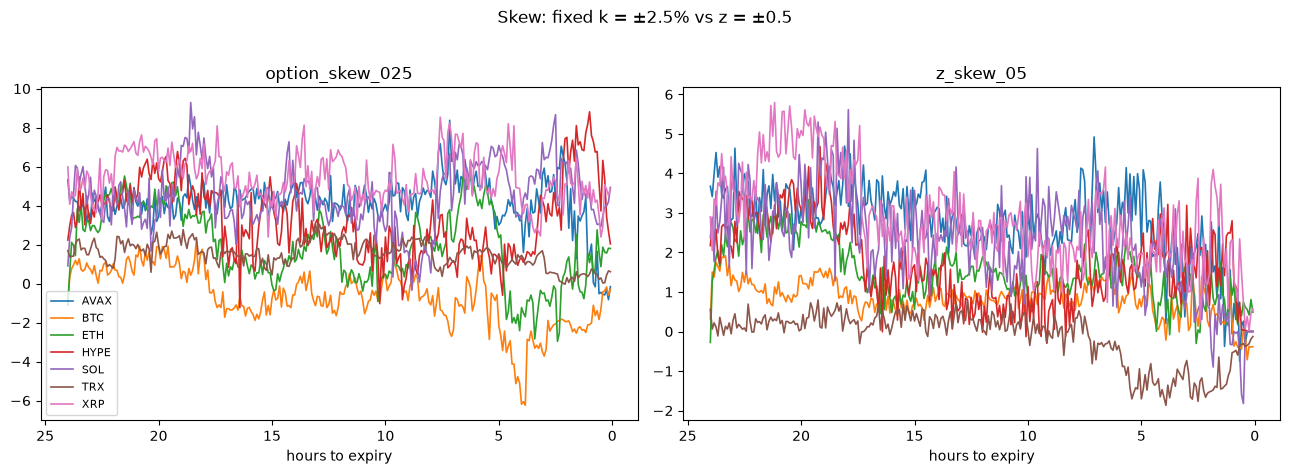

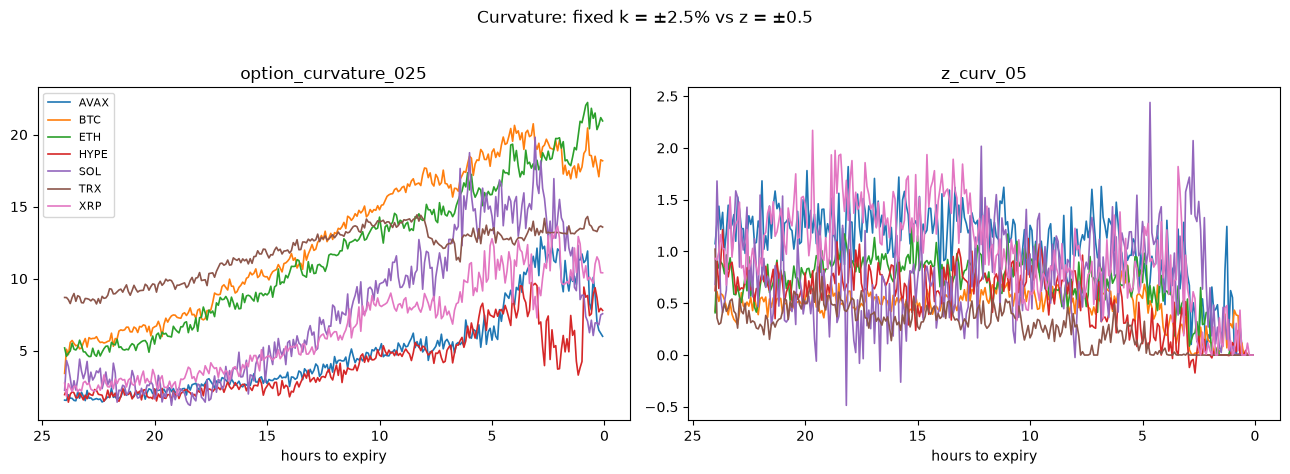

In [56]:
zf["skew_025_rel"] = zf["option_skew_025"] / zf["option_iv_atm_forward"]
zf["curv_025_rel"] = zf["option_curvature_025"] / zf["option_iv_atm_forward"]
zf["z_skew_05_rel"] = zf["z_skew_05"] / zf["option_iv_atm_forward"]
zf["z_curv_05_rel"] = zf["z_curv_05"] / zf["option_iv_atm_forward"]

PAIRS = [
    ("skew", "option_skew_025", "z_skew_05"),
    ("curvature", "option_curvature_025", "z_curv_05"),
    ("skew / ATM", "skew_025_rel", "z_skew_05_rel"),
    ("curvature / ATM", "curv_025_rel", "z_curv_05_rel"),
]

rows = []
for asset, g in zf.groupby("underlying"):
    for label, kcol, zcol in PAIRS:
        both = g.dropna(subset=[kcol, zcol])
        rows.append({
            "underlying": asset, "measure": label, "n_both": len(both),
            "eta2_fixed_k": eta_squared(both, kcol),
            "eta2_z": eta_squared(both, zcol),
        })
stationarity = pd.DataFrame(rows)
stationarity["z_minus_k"] = stationarity["eta2_z"] - stationarity["eta2_fixed_k"]
display(stationarity.round(3))

plot_median_by_tte(zf, ["option_skew_025", "z_skew_05"], "Skew: fixed k = ±2.5% vs z = ±0.5")
plot_median_by_tte(zf, ["option_curvature_025", "z_curv_05"], "Curvature: fixed k = ±2.5% vs z = ±0.5")

# Part F — Dynamics

## 13. Surface-change distributions and the settlement window (audit B4)

Deribit daily options settle to the 30-minute TWAP of the index from 07:30 to 08:00 UTC. During the last six states (`minutes_to_expiry ≤ 30`) part of the settlement price is already fixed, so quotes and implied volatilities stop behaving like those of a European option. The comparison below shows whether level and change distributions break inside that window.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,atm_iv_change_5m,4310,11.968954,-0.011492,1.811659,0.506833,19.683891,-20.638036,-11.144279,-5.426873,-2.345081,-0.020464,2.431283,5.520684,12.866968,19.273770
1,AVAX,atm_iv_change_15m,4200,14.215686,-0.051119,2.558771,1.482665,22.812749,-20.560753,-15.636412,-6.755318,-3.425552,-0.135127,3.583869,8.156216,19.366610,37.388575
2,AVAX,atm_iv_change_1h,3911,20.118464,-0.456743,4.036203,0.565035,6.985835,-23.193689,-21.773092,-10.460414,-6.082373,-0.557803,6.210648,11.616988,20.647161,36.603605
3,AVAX,skew_025_change_5m,4025,17.790033,0.028691,2.414341,0.257411,11.784510,-18.116592,-14.612180,-7.065289,-3.206525,0.000000,3.559959,7.285657,14.946417,21.720640
4,AVAX,skew_025_change_15m,3814,22.099673,0.059295,3.071945,0.951884,16.333966,-22.304751,-16.712356,-8.846866,-4.206678,0.028787,4.497794,9.322838,21.365795,37.396504
5,AVAX,skew_025_change_1h,3328,32.026144,0.123541,4.216631,-0.476942,23.666885,-43.785195,-40.313564,-10.605061,-5.541426,0.061584,5.733753,13.855898,24.624034,41.297329
6,AVAX,curvature_025_change_5m,4025,17.790033,0.028554,1.479486,-0.595322,14.283266,-16.656750,-9.422405,-4.040622,-2.132040,0.032594,2.101408,4.163889,7.697680,13.662130
7,AVAX,curvature_025_change_15m,3814,22.099673,0.128676,1.893810,-2.789141,66.680204,-39.907683,-11.706481,-4.944267,-2.169327,0.125253,2.579474,5.876543,11.448585,15.027277
8,AVAX,curvature_025_change_1h,3328,32.026144,0.443280,2.510457,0.496927,20.825608,-28.176886,-14.329766,-6.582066,-2.289878,0.324240,3.652505,10.045615,17.554880,21.547630
9,AVAX,skew_050_change_5m,4098,16.299020,0.048984,2.984850,0.134641,7.244237,-21.664139,-16.273175,-8.522821,-4.513563,0.000000,4.856373,9.197507,15.019368,24.893690


median_abs                                            p99_abs                                  
segment                          1h before window rest of session settlement window 1h before window rest of session settlement window
feature               underlying                                                                                                      
atm_iv_change_5m      AVAX                  0.622           0.618             0.098            8.397           6.774            15.600
                      BTC                   0.649           0.324             0.624            4.069           2.480             8.234
                      ETH                   0.599           0.372             0.339            3.382           3.060             3.328
                      HYPE                  1.072           0.569             0.046           11.168           8.493             7.763
                      SOL                   0.726           1.255             0.255            9.565           8.475            23.418
                      TRX                   0.093           0.272             0.087            1.690           2.441             1.040
                      XRP                   0.709           0.665             0.250           12.549           5.517            18.566
option_iv_atm_forward AVAX                 72.211          77.547            76.732          125.660         125.353           132.820
                      BTC                  25.758          25.327            27.031           37.053          48.481            42.939
                      ETH                  31.983          32.192            33.805           41.628          59.496            42.216
                      HYPE                 64.308          62.331            63.989           85.799          76.254            86.574
                      SOL                  56.465          53.369            58.966          104.751          84.228           147.858
                      TRX                  23.681          21.681            24.143           36.237          30.468            28.777
                      XRP                  63.074          64.366            61.999          123.356         105.418           128.707
skew_025_change_5m    AVAX                  0.807           0.961             0.835           11.208           9.127            14.230
                      BTC                   0.262           0.400             0.243            3.506           3.258             3.117
                      ETH                   0.512           0.516             0.355            8.264           3.824             3.225
                      HYPE                  0.350           0.825             0.497            6.891          11.450             6.330
                      SOL                   0.480           1.054             0.527            6.001           9.669             5.034
                      TRX                   0.064           0.172             0.062            0.959           2.393             0.925
                      XRP                   0.944           0.973             0.938            9.046           7.504             6.499

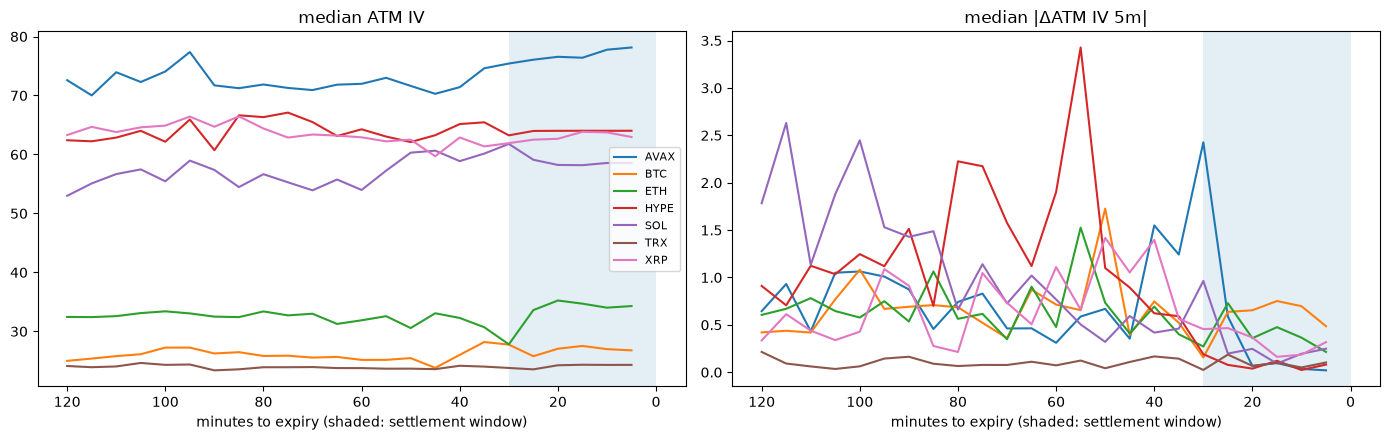

In [57]:
dyn_summary = feature_summary(features, OPTION_DYNAMIC, group_col="underlying")
display(dyn_summary)

settle_rows = []
for asset, g in features.groupby("underlying"):
    for col in ["option_iv_atm_forward", "atm_iv_change_5m", "skew_025_change_5m"]:
        if col not in g.columns:
            continue
        for label, part in [("settlement window", g[g["in_settlement_window"]]),
                            ("1h before window", g[g["minutes_to_expiry"].between(35, 90)]),
                            ("rest of session", g[g["minutes_to_expiry"] > 90])]:
            s = clean_numeric(part, col)
            settle_rows.append({
                "underlying": asset, "feature": col, "segment": label, "n": len(s),
                "median": s.median() if len(s) else np.nan,
                "median_abs": s.abs().median() if len(s) else np.nan,
                "p99_abs": s.abs().quantile(0.99) if len(s) else np.nan,
            })
settlement = pd.DataFrame(settle_rows)
display(settlement.pivot_table(index=["feature", "underlying"], columns="segment", values=["median_abs", "p99_abs"]).round(3))

last = features[features["minutes_to_expiry"] <= 120]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for asset, g in last.groupby("underlying"):
    m = g.groupby("minutes_to_expiry")["option_iv_atm_forward"].median().sort_index(ascending=False)
    axes[0].plot(m.index, m.values, label=asset)
    if "atm_iv_change_5m" in g.columns:
        a = g.groupby("minutes_to_expiry")["atm_iv_change_5m"].apply(lambda s: s.abs().median()).sort_index(ascending=False)
        axes[1].plot(a.index, a.values, label=asset)
for ax, title in zip(axes, ["median ATM IV", "median |ΔATM IV 5m|"]):
    ax.axvspan(0, 30, alpha=0.12)
    ax.invert_xaxis()
    ax.set_xlabel("minutes to expiry (shaded: settlement window)")
    ax.set_title(title)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 14. Persistence within the session

Level features that are persistent are candidate **structural** inputs; changes with near-zero autocorrelation behave like innovations. All autocorrelations are computed on the exact 5-minute grid and never cross the 08:00 boundary.

In [ ]:
acf_frames = []
for col in [c for c in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025", "rr_25d",
                        "atm_iv_change_5m", "skew_025_change_5m"] if c in features.columns]:
    acf_frames.append(within_session_acf(features, col, max_lag=24))
for col in ["z_skew_05", "z_curv_05"]:
    acf_frames.append(within_session_acf(zf, col, max_lag=24))
option_acf = pd.concat(acf_frames, ignore_index=True)

summary_lags = [5, 30, 60, 120]
display(
    option_acf[option_acf["lag_minutes"].isin(summary_lags)]
    .pivot_table(index=["feature", "underlying"], columns="lag_minutes", values="acf")
    .round(3)
)

feats = option_acf["feature"].unique()
fig, axes = plt.subplots(math.ceil(len(feats) / 2), 2, figsize=(14, 3.6 * math.ceil(len(feats) / 2)))
for ax, feat in zip(np.atleast_1d(axes).ravel(), feats):
    for asset, g in option_acf[option_acf["feature"] == feat].groupby("underlying"):
        ax.plot(g["lag_minutes"], g["acf"], linewidth=1, label=asset)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(feat, fontsize=10)
np.atleast_1d(axes).ravel()[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part G — Robustness

## 15. Linear USDC vs inverse families (BTC, ETH)

BTC and ETH list both linear USDC and inverse options for the same expiry. The primary family is linear USDC. If both families give the same ATM IV and the same changes, the primary-family choice is harmless; a persistent gap or weak change correlation would mean one family's surface is dominated by stale or mark-sourced quotes.

In [ ]:
fam_cols = relation_columns("option_surface_feature_state")
if {"iv_atm_forward", "option_family_id", "state_id"}.issubset(fam_cols):
    fam = q(
        """
        SELECT state_id, state_time, underlying, option_family_id, instrument_type,
               iv_atm_forward, atm_iv_change_5m
        FROM option_surface_feature_state
        WHERE underlying IN ('BTC', 'ETH')
        """,
        "BTC/ETH families",
    )
    fam["family"] = np.where(fam["instrument_type"].str.lower().eq("linear"), "linear", "inverse")
    wide = fam.pivot_table(index=["underlying", "state_id"], columns="family",
                           values=["iv_atm_forward", "atm_iv_change_5m"], aggfunc="first")
    if {("iv_atm_forward", "linear"), ("iv_atm_forward", "inverse")}.issubset(wide.columns):
        wide["atm_gap"] = wide[("iv_atm_forward", "linear")] - wide[("iv_atm_forward", "inverse")]
        out = []
        for asset, g in wide.groupby(level="underlying"):
            ch = g[[("atm_iv_change_5m", "linear"), ("atm_iv_change_5m", "inverse")]].dropna()
            out.append({
                "underlying": asset,
                "states_both": int(g["atm_gap"].notna().sum()),
                "median_gap": g["atm_gap"].median(),
                "mad_gap": 1.4826 * (g["atm_gap"] - g["atm_gap"].median()).abs().median(),
                "p99_abs_gap": g["atm_gap"].abs().quantile(0.99),
                "corr_5m_changes": ch.corr().iloc[0, 1] if len(ch) > 20 else np.nan,
            })
        family_comparison = pd.DataFrame(out)
        display(family_comparison.round(4))
    else:
        family_comparison = pd.DataFrame()
        print("Only one family present for BTC/ETH; comparison skipped.")
else:
    family_comparison = pd.DataFrame()
    print("option_surface_feature_state lacks the needed columns; comparison skipped.")

## 16. Level drift across sessions

Median ATM IV and skew per session. Large session-to-session level shifts are expected in crypto (volatility regimes); they matter here because any later normalization must be fitted on training history only.

In [ ]:
session_levels = (
    features.groupby(["expiry_date", "underlying"])[
        [c for c in ["option_iv_atm_forward", "option_skew_025", "rr_25d"] if c in features.columns]
    ]
    .median()
    .unstack("underlying")
)
display(session_levels.round(3))

fig, ax = plt.subplots(figsize=(13, 4.5))
for asset in ASSETS:
    s = features[features["underlying"] == asset].groupby("expiry_date")["option_iv_atm_forward"].median()
    ax.plot(s.index, s.values, marker="o", ms=3, label=asset)
ax.set_title("Median ATM IV per session")
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

# Part H — Addendum: Surface Measurement Quality

The first run of this notebook (16 sessions, surfaces v0.1) found:

- 92–100% of core nodes are mark-sourced in the last hour;
- 5m changes across a quote ↔ mark switch have 3–4× the tail of same-source changes;
- alt 5m ATM changes have lag-1 autocorrelation of about −0.3, the signature of measurement noise;
- BTC/ETH linear and inverse families agree in level but their 5m ATM changes correlate at only 0.04 / 0.13, with BTC ATM IV spikes up to 457%.

From surfaces v0.2 / option features v0.2.0 the pipeline records the IV source of every node, computes changes only when all nodes keep their source class, and no longer requires the futures stream. This part checks those changes on the real data and prototypes a fitted smile as the candidate answer to audit A2.

> Requires a rebuild with `build_features.py --refresh-upstream` (canonical, normalization and surface view definitions changed).

## 17. IV-source composition and blocked changes (pipeline v0.2)

`node_mark_share` is the share of interpolated nodes with at least one mark-sourced side; `base_mark_iv_row_share` the share of surface-eligible contracts priced by the mark model; `core_source_switch_5m` marks contiguous states whose core change was withheld because a node changed source.

In [ ]:
NEW_COLS = ["node_mark_share", "base_mark_iv_row_share", "core_nodes_with_mark",
            "core_source_switch_5m", "atm_source_switch_5m", "src_k_000", "core_iv_source_signature",
            "in_settlement_window", "option_snapshot_ready"]
missing_new = [c for c in NEW_COLS if c not in features.columns]
PIPELINE_V02 = not missing_new
if not PIPELINE_V02:
    print(f"Feature table predates surfaces v0.2 (missing {missing_new}).")
    print("Rebuild with build_features.py --refresh-upstream; Sections 17-19 are partly skipped.")
else:
    src_tab = (
        features[features["core_smile_usable"].fillna(False).astype(bool)]
        .groupby(["underlying", "tte_bucket"], observed=True)
        .agg(
            node_mark_pct=("node_mark_share", lambda s: 100 * s.mean()),
            core_any_mark_pct=("core_nodes_with_mark", lambda s: 100 * (s > 0).mean()),
            row_mark_pct=("base_mark_iv_row_share", lambda s: 100 * s.mean()),
        )
        .round(1)
    )
    display(src_tab.unstack("tte_bucket"))

    blocked = features.groupby("underlying").agg(
        core_changes_5m=("core_surface_change_5m_ready", lambda s: int(s.fillna(False).astype(bool).sum())),
        core_blocked_by_switch=("core_source_switch_5m", lambda s: int(s.fillna(False).astype(bool).sum())),
        atm_blocked_by_switch=("atm_source_switch_5m", lambda s: int(s.fillna(False).astype(bool).sum())),
    )
    blocked["blocked_pct"] = 100 * blocked["core_blocked_by_switch"] / (
        blocked["core_changes_5m"] + blocked["core_blocked_by_switch"]
    )
    display(blocked.round(2))

    print("Core-node source signatures (top 8 per asset, % of usable states):")
    sig = (
        features[features["core_smile_usable"].fillna(False).astype(bool)]
        .groupby("underlying")["core_iv_source_signature"]
        .value_counts(normalize=True)
        .mul(100).round(1)
        .groupby(level=0).head(8)
    )
    display(sig.to_frame("pct"))

    # Option-side recovery from decoupling the futures gate (audit B1).
    recov = features.assign(
        opt=features["option_snapshot_ready"].fillna(False).astype(bool),
        res=features["state_research_ready"].fillna(False).astype(bool),
        core=features["core_smile_usable"].fillna(False).astype(bool),
    )
    display(
        recov.groupby("underlying").agg(
            core_usable=("core", "sum"),
            core_usable_without_futures=("core", lambda s: int((s & ~recov.loc[s.index, "res"]).sum())),
        )
    )

## 18. Is a 5-minute surface change signal or noise?

If an observed level is $y_t = s_t + n_t$, with $s_t$ a random walk and $n_t$ white measurement noise, the 5-minute change has lag-1 autocorrelation

$$
\rho_1 = -\frac{\sigma_n^2}{\sigma_{\Delta s}^2 + 2\sigma_n^2}
\quad\Longrightarrow\quad
\frac{\sigma_n^2}{\sigma_{\Delta s}^2} = \frac{-\rho_1}{1 + 2\rho_1}, \qquad -\tfrac12 < \rho_1 < 0 .
$$

The table reports $\rho_1$ and the implied noise-to-signal variance ratio for ATM, skew and curvature changes. With the v0.2 pipeline these changes are source-consistent, so any remaining noise comes from quotes and interpolation rather than source switches. Positive $\rho_1$ is reported as "no noise signature".

In [ ]:
def lag1_noise(df, column):
    """Lag-1 within-session autocorrelation of a change series and the implied noise ratio."""
    a = within_session_acf(df, column, max_lag=1)
    a["rho1"] = a["acf"]
    a["noise_to_signal_var"] = np.where(
        (a["rho1"] > -0.5) & (a["rho1"] < 0), -a["rho1"] / (1 + 2 * a["rho1"]), np.nan
    )
    return a[["underlying", "feature", "rho1", "noise_to_signal_var", "n_pairs"]]

noise_tab = pd.concat(
    [lag1_noise(features, c) for c in ["atm_iv_change_5m", "skew_025_change_5m", "curvature_025_change_5m", "rr_25d_change_5m"]
     if c in features.columns],
    ignore_index=True,
)
display(noise_tab.pivot(index="underlying", columns="feature", values=["rho1", "noise_to_signal_var"]).round(3))

## 19. ATM spikes and family agreement, measured robustly

The first run showed BTC ATM IV reaching 457% and a near-zero correlation between linear and inverse 5m ATM changes. Pearson correlation is dominated by a handful of extreme values, so agreement is re-measured with:

- **Spearman** rank correlation (insensitive to spikes);
- **Pearson after trimming** the 0.5% largest absolute changes in either family;
- separately for 5m, 15m and 1h changes (if the 5m disagreement is noise, longer horizons should agree better);
- by time-to-expiry bucket.

The spike table lists the most extreme ATM observations with their context.

In [ ]:
spike_cols = [c for c in [
    "state_time", "underlying", "minutes_to_expiry", "option_iv_atm_forward", "atm_iv_change_5m",
    "src_k_000", "core_iv_source_signature", "core_max_interpolation_span",
    "option_base_eligible_rows", "option_two_sided_eligible_rows",
    "option_median_two_sided_spread_bps", "realized_vol_1h_annualized",
] if c in features.columns]
for asset in ["BTC", "ETH"]:
    g = features[features["underlying"] == asset]
    print(f"\n{asset}: highest ATM IV states")
    display(g.nlargest(10, "option_iv_atm_forward")[spike_cols])
    print(f"{asset}: largest |ΔATM IV 5m|")
    display(g.loc[g["atm_iv_change_5m"].abs().nlargest(10).index, spike_cols])

fam2 = q(
    """
    SELECT state_id, state_time, underlying, session_id, minutes_to_expiry, instrument_type,
           iv_atm_forward, atm_iv_change_5m, atm_iv_change_15m, atm_iv_change_1h
    FROM option_surface_feature_state
    WHERE underlying IN ('BTC', 'ETH')
    """,
    "BTC/ETH family changes",
)
fam2["family"] = np.where(fam2["instrument_type"].str.lower().eq("linear"), "linear", "inverse")
fam2["tte_bucket"] = pd.cut(fam2["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)

agree_rows = []
for horizon in ["atm_iv_change_5m", "atm_iv_change_15m", "atm_iv_change_1h"]:
    w = fam2.pivot_table(index=["underlying", "state_id", "tte_bucket"], columns="family",
                         values=horizon, aggfunc="first", observed=True).dropna()
    if not {"linear", "inverse"}.issubset(w.columns):
        continue
    for (asset, bucket), g in w.groupby(level=["underlying", "tte_bucket"], observed=True):
        if len(g) < 30:
            continue
        lim_l, lim_i = g["linear"].abs().quantile(0.995), g["inverse"].abs().quantile(0.995)
        trimmed = g[(g["linear"].abs() <= lim_l) & (g["inverse"].abs() <= lim_i)]
        agree_rows.append({
            "underlying": asset, "horizon": horizon.replace("atm_iv_change_", ""), "tte_bucket": bucket,
            "n": len(g),
            "pearson": g["linear"].corr(g["inverse"]),
            "pearson_trimmed": trimmed["linear"].corr(trimmed["inverse"]),
            "spearman": g["linear"].corr(g["inverse"], method="spearman"),
        })
family_agreement = pd.DataFrame(agree_rows)
if not family_agreement.empty:
    display(
        family_agreement.pivot_table(index=["underlying", "tte_bucket"], columns="horizon",
                                     values="spearman", observed=True).round(3)
    )
    display(
        family_agreement.groupby(["underlying", "horizon"])[["pearson", "pearson_trimmed", "spearman"]]
        .median().round(3)
    )

## 20. Fitted smile in standardized moneyness (A2 candidate)

Node interpolation uses two strikes per node, so near expiry, when strikes are several $\sigma\sqrt\tau$ apart, it manufactures curvature and noise (Section 12). A least-squares fit uses every quoted strike at once. For each state and option family:

$$
\sigma(z) = a + b\,z + c\,z^2, \qquad z = \frac{\ln(K/F)}{\sigma_{ATM}\sqrt{\tau}},
$$

fitted by weighted least squares on **quote-sourced** OTM contracts (bid/ask-IV midpoint) with $|z| \le 2$, with weights $w_i = 1 / \max(\text{IV spread}_i,\ 0.5)^2$, so tight quotes count more. Mark-model IVs are excluded by construction.

- $a$ is the fitted ATM level, $b$ the skew per expected move, $c$ the curvature per expected move squared;
- a fit is accepted only with at least `FIT_MIN_POINTS` quotes and strikes on both sides ($z_{\min} \le -0.5$, $z_{\max} \ge 0.5$);
- the scale $\sigma_{ATM}$ comes from the pipeline's interpolated ATM IV of the same family (a prototype shortcut; a production version would iterate or use the fit itself).

This is a quadratic special case of the SVI family the framework names; it is not arbitrage-checked.

In [ ]:
FIT_Z_MAX = 2.0
FIT_MIN_POINTS = 5
FIT_SPREAD_FLOOR = 0.5   # IV points
FIT_FAMILIES_EXTRA = ["BTC|reversed|BTC|BTC", "ETH|reversed|ETH|ETH"]

fit_chain = q(
    f"""
    WITH fams AS (
        SELECT DISTINCT option_family_id FROM primary_option_surface_feature_state
        UNION
        SELECT option_family_id FROM (VALUES {", ".join(f"('{f}')" for f in FIT_FAMILIES_EXTRA)}) t(option_family_id)
    ),
    atm AS (
        SELECT state_id, option_family_id, iv_atm_forward, minutes_to_expiry
        FROM option_surface_feature_state
        WHERE iv_atm_forward > 0
    )
    SELECT
        n.state_id, n.option_family_id, n.log_moneyness, n.iv_mid, n.iv_spread,
        a.iv_atm_forward, a.minutes_to_expiry
    FROM normalized_option_chain n
    JOIN fams f ON n.option_family_id = f.option_family_id
    JOIN atm a ON a.state_id = n.state_id AND a.option_family_id = n.option_family_id
    WHERE n.surface_base_eligible
      AND n.preferred_iv_source = 'bid_ask_iv_mid'
      AND n.iv_mid > 0
    """,
    "quote-sourced chain for fits",
)

fc = fit_chain
fc["scale"] = fc["iv_atm_forward"] * IV_TO_DECIMAL * np.sqrt(fc["minutes_to_expiry"] / MINUTES_PER_YEAR)
fc["z"] = fc["log_moneyness"] / fc["scale"]
fc = fc[fc["z"].abs() <= FIT_Z_MAX].copy()
fc["w"] = 1.0 / np.maximum(fc["iv_spread"].fillna(FIT_SPREAD_FLOOR * 4), FIT_SPREAD_FLOOR) ** 2
fc["y"] = fc["iv_mid"]
for p in range(5):
    fc[f"wz{p}"] = fc["w"] * fc["z"] ** p
for p in range(3):
    fc[f"wyz{p}"] = fc["w"] * fc["y"] * fc["z"] ** p

keys = ["state_id", "option_family_id"]
agg = fc.groupby(keys).agg(
    n=("z", "size"), z_min=("z", "min"), z_max=("z", "max"),
    **{f"S{p}": (f"wz{p}", "sum") for p in range(5)},
    **{f"T{p}": (f"wyz{p}", "sum") for p in range(3)},
).reset_index()

A = np.stack([
    np.stack([agg["S0"], agg["S1"], agg["S2"]], axis=-1),
    np.stack([agg["S1"], agg["S2"], agg["S3"]], axis=-1),
    np.stack([agg["S2"], agg["S3"], agg["S4"]], axis=-1),
], axis=1)
B = np.stack([agg["T0"], agg["T1"], agg["T2"]], axis=-1)
ok = (agg["n"] >= FIT_MIN_POINTS) & (agg["z_min"] <= -0.5) & (agg["z_max"] >= 0.5)
det = np.linalg.det(A)
ok &= np.abs(det) > 1e-12
coef = np.full((len(agg), 3), np.nan)
coef[ok.to_numpy()] = np.linalg.solve(A[ok.to_numpy()], B[ok.to_numpy()][..., None])[..., 0]
agg["fit_a"], agg["fit_b"], agg["fit_c"] = coef[:, 0], coef[:, 1], coef[:, 2]
agg["fit_ok"] = ok

res = fc.merge(agg[keys + ["fit_a", "fit_b", "fit_c"]], on=keys)
res["r2"] = res["w"] * (res["y"] - (res["fit_a"] + res["fit_b"] * res["z"] + res["fit_c"] * res["z"] ** 2)) ** 2
sums = res.groupby(keys)[["r2", "w"]].sum()
rmse = np.sqrt(sums["r2"] / sums["w"])
agg = agg.merge(rmse.rename("fit_wrmse").reset_index(), on=keys, how="left")
fits = agg[keys + ["n", "z_min", "z_max", "fit_ok", "fit_a", "fit_b", "fit_c", "fit_wrmse"]]
print(f"Family-states with a quote chain: {len(fits):,} | accepted fits: {int(fits['fit_ok'].sum()):,}")

## 21. Fitted smile vs node features

Four tests, each against the current fixed-$k$ (and, where relevant, delta) features:

1. **Coverage** by time to expiry — the fit needs quotes on both sides, which may fail near expiry where only mark IVs remain.
2. **Clock dependence** ($\eta^2$) of skew $b/a$ and curvature $c/a$.
3. **Noise** — lag-1 autocorrelation of 5m changes in $a$, $b$, $c$ (Section 18 formula).
4. **Family agreement** — Spearman correlation of 5m and 15m changes in $a$ and $b$ between BTC/ETH linear and inverse families.

A fitted smile is the better representation if it keeps reasonable coverage while lowering clock dependence and noise and raising family agreement.

In [ ]:
prim_fits = fits.merge(
    features[["state_id", "primary_option_family_id", "underlying", "session_id", "state_time",
              "minutes_to_expiry", "tte_bucket", "option_iv_atm_forward", "option_skew_025",
              "option_curvature_025", "rr_25d", "core_smile_usable"]],
    left_on=["state_id", "option_family_id"], right_on=["state_id", "primary_option_family_id"], how="right",
)
prim_fits.loc[~prim_fits["fit_ok"].fillna(False).astype(bool), ["fit_a", "fit_b", "fit_c"]] = np.nan
prim_fits["fit_skew_rel"] = prim_fits["fit_b"] / prim_fits["fit_a"]
prim_fits["fit_curv_rel"] = prim_fits["fit_c"] / prim_fits["fit_a"]
prim_fits["k_skew_rel"] = prim_fits["option_skew_025"] / prim_fits["option_iv_atm_forward"]
prim_fits["k_curv_rel"] = prim_fits["option_curvature_025"] / prim_fits["option_iv_atm_forward"]

# 1) coverage
cov = prim_fits.groupby(["underlying", "tte_bucket"], observed=True).agg(
    fit_pct=("fit_a", lambda s: 100 * s.notna().mean()),
    fixed_k_core_pct=("core_smile_usable", lambda s: 100 * s.fillna(False).astype(bool).mean()),
    delta25_pct=("rr_25d", lambda s: 100 * s.notna().mean()),
    median_quotes=("n", "median"),
    median_wrmse=("fit_wrmse", "median"),
).round(2)
display(cov)
print("Median |fit a − pipeline ATM IV| (IV points):",
      round(float((prim_fits["fit_a"] - prim_fits["option_iv_atm_forward"]).abs().median()), 3))

# 2) clock dependence
eta_rows = []
for asset, g in prim_fits.groupby("underlying"):
    for label, kc, fcol in [("skew / ATM", "k_skew_rel", "fit_skew_rel"),
                            ("curvature / ATM", "k_curv_rel", "fit_curv_rel")]:
        both = g.dropna(subset=[kc, fcol])
        eta_rows.append({"underlying": asset, "measure": label, "n_both": len(both),
                         "eta2_fixed_k": eta_squared(both, kc), "eta2_fit": eta_squared(both, fcol)})
fit_eta = pd.DataFrame(eta_rows)
display(fit_eta.round(3))

# 3) noise in 5m changes
prim_fits = prim_fits.sort_values(["underlying", "state_time"])
for col in ["fit_a", "fit_b", "fit_c"]:
    prev = prim_fits.groupby("underlying")[col].shift(1)
    contiguous = (
        (prim_fits["state_time"] - prim_fits.groupby("underlying")["state_time"].shift(1) == pd.Timedelta(minutes=5))
        & (prim_fits["session_id"] == prim_fits.groupby("underlying")["session_id"].shift(1))
    )
    prim_fits[f"d_{col}_5m"] = (prim_fits[col] - prev).where(contiguous)
fit_noise = pd.concat(
    [lag1_noise(prim_fits, c) for c in ["d_fit_a_5m", "d_fit_b_5m", "d_fit_c_5m"]]
    + [lag1_noise(features, "atm_iv_change_5m"), lag1_noise(features, "skew_025_change_5m")],
    ignore_index=True,
)
display(fit_noise.pivot(index="underlying", columns="feature", values="rho1").round(3))

# 4) family agreement of fitted parameters (BTC, ETH)
fam_fit = fits.merge(
    fam2[["state_id", "underlying", "session_id", "state_time", "family", "instrument_type"]]
    .assign(option_family_id=lambda d: np.where(d["family"] == "linear",
                                                d["underlying"] + "|linear|USDC|USDC",
                                                d["underlying"] + "|reversed|" + d["underlying"] + "|" + d["underlying"])),
    on=["state_id", "option_family_id"], how="inner",
)
fam_fit.loc[~fam_fit["fit_ok"].fillna(False).astype(bool), ["fit_a", "fit_b"]] = np.nan
fam_fit = fam_fit.sort_values(["option_family_id", "state_time"])
fit_agree = []
for lag, label in [(1, "5m"), (3, "15m")]:
    for col in ["fit_a", "fit_b"]:
        g = fam_fit.groupby("option_family_id")
        ok_lag = (
            (fam_fit["state_time"] - g["state_time"].shift(lag) == pd.Timedelta(minutes=5 * lag))
            & (fam_fit["session_id"] == g["session_id"].shift(lag))
        )
        fam_fit[f"d_{col}_{label}"] = (fam_fit[col] - g[col].shift(lag)).where(ok_lag)
        w = fam_fit.pivot_table(index=["underlying", "state_id"], columns="family",
                                values=f"d_{col}_{label}", aggfunc="first").dropna()
        for asset, gg in w.groupby(level="underlying"):
            if {"linear", "inverse"}.issubset(gg.columns) and len(gg) > 30:
                fit_agree.append({"underlying": asset, "parameter": col, "horizon": label, "n": len(gg),
                                  "spearman": gg["linear"].corr(gg["inverse"], method="spearman")})
fit_family_agreement = pd.DataFrame(fit_agree)
display(fit_family_agreement.pivot_table(index=["underlying", "parameter"], columns="horizon", values="spearman").round(3)
        if not fit_family_agreement.empty else fit_family_agreement)

plot_median_by_tte(prim_fits, ["fit_skew_rel", "k_skew_rel"], "Skew / ATM: fitted (b/a) vs fixed k")
plot_median_by_tte(prim_fits, ["fit_curv_rel", "k_curv_rel"], "Curvature / ATM: fitted (c/a) vs fixed k")

# Part I — Research Handoff

## 22. Interpretation checklist

Answer these before Notebook 04:

1. **B1:** how many valid option states does the futures gate remove, and on which dates? Is decoupling surface eligibility from the futures stream justified?
2. **A2:** how far does the ±2.5% node travel in $z$ through the session, and for which assets is it beyond 3σ for most of the day?
3. **A2:** do $z$-space skew and curvature have materially lower $\eta^2$ than the fixed-$k$ versions? For which assets?
4. **A2 trade-off:** where does the $z$-grid lose coverage or need large spans (near expiry, coarse strike grids)?
5. **B2:** what share of core nodes is mark-sourced, by asset and time to expiry? Above what share should an asset's option features be treated as Deribit-model information rather than market information?
6. **B2:** are 5-minute changes across a source switch materially noisier than same-source changes?
7. **B4:** do levels or changes break inside the settlement window?
8. Which option features are persistent enough to be structural, and which behave as innovations?
9. Do the BTC/ETH linear and inverse families agree?
10. Is any of this based on too little history (16 sessions) to support a production decision?
11. **Pipeline v0.2:** what share of 5m core changes is now withheld by source switches, and how many option states did decoupling from the futures gate recover?
12. **Noise:** after source-consistent changes, what noise-to-signal ratio remains in 5m ATM / skew changes? Should structural option dynamics use 15m–1h horizons instead?
13. **Spikes and families:** are the BTC/ETH ATM spikes real? Do families agree once measured robustly, and at which horizon?
14. **Fitted smile (A2):** does the quadratic $z$-fit beat fixed-$k$ and delta on coverage, clock dependence, noise and family agreement? Where does it fail (near expiry, TRX)?

Source-consistent changes (B2), futures decoupling (B1) and the settlement flag (B4) are implemented in surfaces v0.2 / option features v0.2.0. **The representation decision (A2: fixed-$k$, delta or fitted $z$-smile) is not made here**; it is a `src/` change to be proposed with Sections 20–21 as evidence.

In [ ]:
surface_distribution_report = {
    "futures_gate_loss": gate,
    "availability_by_tte": availability.reset_index(),
    "level_by_asset": level_by_asset,
    "z_of_k025_by_tte": z_table.reset_index(),
    "eta2_fixed": eta_fixed.reset_index(),
    "core_mark_share_by_tte": mark_share.reset_index(),
    "source_switch_changes": switch_summary.reset_index(),
    "z_grid_coverage": z_cov.reset_index(),
    "stationarity_k_vs_z": stationarity,
    "settlement_window": settlement,
    "option_acf": option_acf,
    "family_comparison": family_comparison,
    "noise_ratio": noise_tab,
    "family_agreement_robust": family_agreement,
    "fit_coverage": cov.reset_index(),
    "fit_eta2": fit_eta,
    "fit_noise": fit_noise,
    "fit_family_agreement": fit_family_agreement,
}
print("Surface-distribution report sections:")
for name, frame in surface_distribution_report.items():
    print(f"  {name:<26} {len(frame):>8,} rows")

## 23. Close the read-only connection

In [ ]:
con.close()
print("DuckDB connection closed.")